# B7q · Docking the 82 nitrosamines into CYP2A13: does the geometry for activation track carcinogenic potency?
**Series B, Post 7q** &nbsp;|&nbsp; follows B7p (docking to the α7 nicotinic receptor)

**Why this enzyme instead of a receptor.** A nitrosamine does not cause cancer by itself: a cytochrome P450 has to hydroxylate one of the carbons next to the N-nitroso group (the $\alpha$-carbons), and the resulting unstable product turns into an alkylating agent that damages DNA. For the tobacco-specific nitrosamines NNK and NNN this step is catalysed by CYP2A13 and CYP2A6, and CYP2A13 is the more efficient enzyme; crystal structures of CYP2A13 with NNK itself are available (Scott laboratory, *J. Biol. Chem.* 2012). The step is also the one that sets the potency, which makes an enzyme a better candidate than the α7 receptor of B7p, where binding is related to tumour promotion in the lung.

**What a docking calculation can and cannot say about it.** A P450 reaction needs three things: the substrate must *bind* (the Vina score), it must bind in a pose that puts an $\alpha$-C–H bond **close to the heme iron** (the geometry), and the C–H bond must be *reactive* (not modelled here). Binding strength alone does not set the reaction rate, so besides the Vina score the notebook computes **geometry features** for each docked pose: the distance from the nearest $\alpha$-carbon to the heme iron, and the fraction of poses in which an $\alpha$-carbon is within 6 Å of the iron (a typical distance between the iron and the carbon that is oxidised is around 4 to 6 Å). Hydrogens on carbon are not kept by the docking software, so the $\alpha$-**carbon** is the proxy for the hydrogens.

**Limits that apply from the start.** (i) CYP2A13 is an enzyme of the respiratory tract with a small hydrophobic pocket, and is mainly relevant to NNK-like and nicotine-like molecules; the small dialkylnitrosamines are mostly activated by CYP2E1 and others, so for many of the 82 compounds CYP2A13 is not the enzyme that matters. (ii) The structure is human, the TD$_{50}$ values are from rats. (iii) Vina scores are rough, and the P450 reaction depends on much more than the geometry. A null result will therefore be the more likely one; the notebook is built so that it is informative.

**What the notebook does.** (1) rebuilds the 82-nitrosamine table; (2) downloads the CYP2A13–NNK structure (PDB 4EJH, 2.35 Å), finds the NNK molecule that sits in the active site next to the heme, prepares a rigid receptor *with the heme*; (3) **validates** the protocol by redocking NNK and comparing the pose and its $\alpha$-carbon to iron distance with the crystal; (4) docks all 82 nitrosamines, keeping several poses and conformers; (5) tests the correlations with the pTD$_{50}$ **while controlling for molecular size**, for the score and for the geometry features.

> **Not for regulatory use, and not a measurement of metabolism.** Nothing here shows that a nitrosamine is a CYP2A13 substrate or how fast it is activated.

**Stop and predict:** (1) In the crystal structure, how far is the nearest $\alpha$-carbon of NNK from the heme iron? (2) Will the geometry features correlate with the pTD$_{50}$ better than the Vina score does? (3) Which has the better chance of surviving a correction for the molecular size?

## 0. Setup: the programs of the official AutoDock Vina Colab examples, installed in a way that works now
The official AutoDock Vina Colab examples prepare ligands with Molscrub's `scrub.py` and Meeko, and the receptor with **reduce2** (hydrogens) and Meeko's `mk_prepare_receptor.py`. Their installation route (condacolab and a setup script) **currently fails on Colab runtimes with Python 3.13**: condacolab pins the base Python to 3.13, and the Meeko version in the setup script's conda environment needs Python below 3.12, so the solver stops and nothing is installed. This notebook therefore installs the same programs differently:

* **pip** installs RDKit, Meeko, Molscrub and the analysis packages into the notebook's own Python (about 1 minute);
* **micromamba** creates a **separate** Python 3.11 environment that only contains `cctbx-base`, the package that provides `reduce2` (about 4 minutes); the notebook's own Python is not touched, so no kernel restart is needed, and the Phenix `geostd` library that reduce2 needs is cloned next to the notebook;
* if reduce2 cannot be installed or fails, the receptor hydrogens are added with **PDBFixer** instead (a different but standard program; the notebook says which one was used);
* AutoDock Vina itself runs as a downloaded executable, as before.

Run the first two cells, then go on. If you re-run the notebook in the same session, you can skip them.

In [ ]:
# @title (1) Install the Python packages (about 1 minute)
%%time
! pip install -q rdkit meeko gemmi molscrub scikit-learn scipy

In [2]:
# @title (2) Install reduce2 in a separate Python 3.11 environment with micromamba (about 4 minutes)
%%time
! curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C /content bin/micromamba
! /content/bin/micromamba create -y -q -r /content/mamba -n reduce -c conda-forge python=3.11 cctbx-base
! test -d geostd || git clone -q https://github.com/phenix-project/geostd.git

CPU times: user 239 ms, sys: 29.5 ms, total: 268 ms
Wall time: 1min 51s


**Third cell: imports and the command-line tools.** The cell below finds `scrub.py` (ligand protonation and 3D conformers) and `mk_prepare_receptor.py` (receptor conversion), looks for `reduce2` in the separate environment, and defines `add_hydrogens`, which uses reduce2 when it is available and PDBFixer otherwise. If `scrub.py` or `mk_prepare_receptor.py` cannot be found, the first cell did not finish: run it again.

In [3]:
import os, sys, subprocess, importlib.util, math, time, json, re, io, warnings, urllib.request, shutil, platform, hashlib, sysconfig
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); np.set_printoptions(precision=3, suppress=True, linewidth=120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")
def pip(*pkgs):
    try: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs]); return True
    except Exception as e_: print("pip install failed for", pkgs, "-", type(e_).__name__); return False
for mod, pkg in [("rdkit", "rdkit"), ("meeko", "meeko"), ("gemmi", "gemmi"), ("molscrub", "molscrub"), ("sklearn", "scikit-learn"), ("scipy", "scipy")]:
    if importlib.util.find_spec(mod) is None: pip(pkg)
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, Descriptors, Crippen, rdMolDescriptors, rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
import rdkit, meeko; print("python", platform.python_version(), "| rdkit", rdkit.__version__, "| meeko", getattr(meeko, "__version__", "?"))
def find_script(name):
    for d in (sysconfig.get_path("scripts"), os.path.dirname(sys.executable), "/usr/local/bin"):
        if (Path(d) / name).exists(): print("using", name, "at", Path(d) / name); return Path(d) / name
    if shutil.which(name): print("using", name, "at", shutil.which(name)); return Path(shutil.which(name))
    raise FileNotFoundError(f"cannot find {name}; run the first setup cell (pip install) again")
SCRUB = find_script("scrub.py"); MK_PREPARE_RECEPTOR = find_script("mk_prepare_receptor.py")
MICROMAMBA, MAMBA_ROOT = Path("/content/bin/micromamba"), Path("/content/mamba"); GEOSTD = Path.cwd() / "geostd"
REDUCE2 = next(iter((MAMBA_ROOT / "envs" / "reduce").glob("lib/python3.*/site-packages/mmtbx/command_line/reduce2.py")), None)
print("reduce2:", REDUCE2 if REDUCE2 else "NOT FOUND (PDBFixer will add the hydrogens)", "| geostd:", GEOSTD.exists())
def add_hydrogens(in_pdb, out_pdb):
    """reduce2 (as in the official examples) if it is available, otherwise PDBFixer; returns the name of the program that was used"""
    if REDUCE2 is not None and GEOSTD.exists() and MICROMAMBA.exists():
        env = dict(os.environ, MMTBX_CCP4_MONOMER_LIB=str(GEOSTD))
        r = subprocess.run([str(MICROMAMBA), "run", "-r", str(MAMBA_ROOT), "-n", "reduce", "python", str(REDUCE2), in_pdb, "approach=add", "add_flip_movers=True"], capture_output=True, text=True, env=env)
        expected = in_pdb[:-4] + "FH.pdb"
        if os.path.isfile(expected):
            if os.path.abspath(expected) != os.path.abspath(out_pdb): shutil.copy(expected, out_pdb)         # reduce2 names its output <input>FH.pdb
            return "reduce2"
        print("reduce2 did not write", expected, "-", (r.stdout + r.stderr)[-400:].replace("\n", " "))
    if importlib.util.find_spec("pdbfixer") is None: pip("pdbfixer")
    from pdbfixer import PDBFixer
    from openmm.app import PDBFile
    fx = PDBFixer(filename=in_pdb); fx.findMissingResidues(); fx.missingResidues = {}; fx.findNonstandardResidues(); fx.replaceNonstandardResidues(); fx.removeHeterogens(False); fx.findMissingAtoms(); fx.addMissingAtoms(); fx.addMissingHydrogens(7.4)
    with open(out_pdb, "w") as fh: PDBFile.writeFile(fx.topology, fx.positions, fh, keepIds=True)
    return "PDBFixer"
FAST = True                         # True: 1 conformer per ligand, exhaustiveness 8; False: 3 conformers, exhaustiveness 16 (several times slower)
N_CONF, EXHAUST, N_POSES = (1, 8, 9) if FAST else (3, 16, 9)
REACTIVE = 6.0                      # an alpha-carbon within this distance (A) of the heme iron counts as a reactive pose
N_CPU = max(1, os.cpu_count() or 1); SEED = 0; print(f"conformers per ligand {N_CONF}, exhaustiveness {EXHAUST}, poses kept {N_POSES}, CPUs {N_CPU}")

python 3.13.18 | rdkit 2026.09.2 | meeko 0.8.0
using scrub.py at /usr/local/bin/scrub.py
using mk_prepare_receptor.py at /usr/local/bin/mk_prepare_receptor.py
reduce2: /content/mamba/envs/reduce/lib/python3.1/site-packages/mmtbx/command_line/reduce2.py | geostd: True
conformers per ligand 1, exhaustiveness 8, poses kept 9, CPUs 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 1. The 82 nitrosamines
The same embedded tables as in B7o and B7p: **82 unique carcinogens** with their molar potency $\mathrm{pTD}_{50}=-\log_{10}(\mathrm{TD}_{50}/(1000\,M_w))$ (larger = more potent), the source of each value (`td50_src`; 53 are rat-specific) and, where available, the regulators' CPCA category. The 15 negative nitrosamines are loaded too, and docked only if `DOCK_NEGATIVES = True`.

In [4]:
POS_CSV = "name|cas|smiles|cpdb|lcdb|s19|gold\nN-Nitroso-methyl-2-phenylethylamine (NMPEA)|13256-11-6|CN(CCC1=CC=CC=C1)N=O|0.00998|0.00797||0.00998\nN-Nitrosomethyl(2-oxopropyl)amine|55984-51-5|CC(=O)CN(C)N=O|0.0172|0.0175|0.017|0.0172\nN-Nitrosodiethylamine (DEN, NDEA)|55-18-5|CCN(CC)N=O|0.0265|0.0177||0.0265\nN-Nitroso(2,3-dihydroxypropyl)(2-oxopropyl)amine|92177-50-9|CC(=O)CN(CC(O)CO)N=O|0.0352||0.0352|0.0352\nN-Nitrosoheptamethyleneimine|20917-49-1|O=NN1CCCCCCC1|0.0378|0.0383||0.0378\nN-Nitrosomethyl-2-hydroxypropylamine|75411-83-5|CC(O)CN(C)N=O|0.0463||0.0442|0.0463\nN-Nitroso-methylethylamine|10595-95-6|CCN(C)N=O|0.0503|||0.0503\nN-Nitroso-2,3-dihydroxypropyl-2-hydroxypropylamine|89911-79-5|CC(O)CN(CC(O)CO)N=O|0.0535|||0.0535\nN-Nitroso-1,2,3,6-tetrahydropyridine (NTHP)|55556-92-8|O=NN1CCC=CC1|0.0601|0.0599||0.0601\nDinitrosohomopiperazine|55557-00-1|O=NN1CCCN(N=O)CC1|0.0615|0.134|0.242|\nN′-Nitrosonornicotine|53759-22-1|O=NN1CCCC1c1cccnc1|||0.0957|0.0957\nN-Nitrosodimethylamine (DMN, NDMA)|62-75-9|CN(C)N=O|0.0959|0.177||0.0959\n4-(Methylnitrosamino)-1-(3-pyridyl)-1-butanone (NNK)|64091-91-4|CN(CCCC(=O)C1=CN=CC=C1)N=O|0.142|0.0999||0.0999\n4-(Methylnitrosoamino)-1-(3-pyridyl)-1-butanol|76014-81-8|CN(CCCC(O)C1=CC=CN=C1)N=O|0.103|||0.103\nN-Methyl-N-nitrosoaniline|614-00-6|CN(N=O)c1ccccc1|0.142|0.106|0.106|0.142\nN-Nitrosomorpholine|59-89-2|O=NN1CCOCC1|0.109|0.135|0.129|0.109\nN-Methyl-N′-nitrosopiperazine|16339-07-4|CN1CCN(N=O)CC1|||0.14|\n1-Nitroso-3,4,5-trimethylpiperazine|75881-18-4|CC1CN(N=O)CC(C)N1C|0.151|0.153|0.153|0.151\nN,N'-Dinitrosohexahydropyrimidine|15973-99-6|O=NN1CCCN(C1)N=O|0.166|0.168||\nN-Nitrosobis(2-oxopropyl)amine|60599-38-4|CC(=O)CN(CC(C)=O)N=O|0.491|0.184|0.286|0.491\nDinitrosocaffeidine|145438-97-7|CN(N=O)C(=O)c1c(N(C)N=O)ncn1C|||0.185|\nN-Nitroso-di-n-propylamine (DPN/NDPA)|621-64-7|CCCN(CCC)N=O|0.186|||0.186\n2-Nitrosomethylaminopyridine|16219-98-0|CN(N=O)C1=NC=CC=C1|0.214|||0.214\nN-Nitroso-N-methyl-4-fluoroaniline|937-25-7|CN(N=O)c1ccc(F)cc1|0.255||0.255|0.255\n4-(Butylnitrosoamino)-1-butanol|3817-11-6|CCCCN(CCCCO)N=O|0.457|0.261||0.457\nN-Nitrosohexamethyleneimine|932-83-2|O=NN1CCCCCC1|||0.313|0.528\nN-Nitrosoallyl-2-oxopropylamine|91308-71-3|C=CCN(CC(C)=O)N=O|0.335||0.335|0.335\n4-(4-N-Methyl-N-nitrosaminostyryl)quinoline|16699-10-8|CN(N=O)c1ccc(/C=C/c2ccnc3ccccc23)cc1|||0.468|0.699\nName not provided in source|81795-07-5|N1(C(SC(SC1C)C)C)N=O||||0.483\n2-(Nitroso-2-propenylamino)ethanol|91308-69-9|OCCN(CC=C)N=O|0.491|||0.491\nN-Nitroso-4-piperidone|55556-91-7|O=NN1CCC(=O)CC1|||0.499|\nMethyldodecylnitrosamine|55090-44-3|CCCCCCCCCCCCN(C)N=O|0.537|||0.537\nN′-Nitrosonornicotine-1-N-oxide|78246-24-9|O=NN1CCCC1c1ccc[n+]([O-])c1|||0.573|0.876\nN-Nitroso-4-piperidinol|55556-93-9|O=NN1CCC(O)CC1|||0.596|\nN-Nitrosomethyl-2,3-dihydroxypropylamine|86451-37-8|CN(CC(O)CO)N=O|0.646||0.646|0.646\n3-Methyl-1-nitrosopiperidine|13603-07-1|CC1CCCN(N=O)C1|||0.665|\n4-Methyl-1-nitrosopiperidine|15104-03-7|CC1CCN(N=O)CC1|||0.665|\nN-Nitrosopyrrolidine|930-55-2|O=NN1CCCC1|0.799|2.02|2.47|0.679\nN-Nitroso-di-n-butylamine (DBN/NDBA)|924-16-3|CCCCN(CCCC)N=O|0.691|||0.691\nN-Nitrosobis (4,4,4-trifluorobutyl) amine|83335-32-4|FC(F)(F)CCCN(CCCC(F)(F)F)N=O|0.748|||0.748\n3-Nitrosooxazolidine|39884-52-1|O=NN1CCOC1|0.798|||0.798\n3-Hydroxy-N-nitrosopiperidine|55556-85-9|O=NN1CCCC(O)C1|||0.819|\nN-Nitrosoallyl-2,3-dihydroxypropylamine|88208-16-6|C=CCN(CC(O)CO)N=O|0.825||0.825|0.825\nN-Nitrosobis(2-hydroxypropyl)amine|53609-64-6|CC(O)CN(CC(C)O)N=O|0.846|1.78|0.891|0.846\n1-Nitroso-3,5-dimethylpiperazine|67774-31-6|CC1CN(N=O)CC(C)N1|||0.866|\n1-(Nitroso-2-propenylamino)-2-propanol|91308-70-2|CC(O)CN(CC=C)N=O|0.877|||0.877\n1-Nitroso-4-acetyl-3,5-dimethylpiperazine|75881-17-3|CC(=O)N1C(C)CN(N=O)CC1C|||0.921|\nN-Nitrosopiperidine|100-75-4|O=NN1CCCCC1||1.12|0.974|1.3\nNitrosomethyl-3-carboxypropylamine|61445-55-4|CN(CCCC(O)=O)N=O|0.982|||0.982\nN-Nitroso(2-hydroxyethyl)(2-oxopropyl)amine|92177-49-6|CC(=O)CN(CCO)N=O|1.8||0.997|0.997\nMononitrosocaffeidine|145438-96-6|CNC(=O)c1c(N(C)N=O)ncn1C|1.01|1|1.01|1\nN-Nitroso(2-hydroxypropyl)(2-hydroxyethyl)amine|75896-33-2|CC(O)CN(CCO)N=O|1.02||1.02|1.02\nN-Nitroso(2-hydroxypropyl)(2-oxopropyl)amine (HPOP)|61499-28-3|CC(=O)CN(CC(C)O)N=O|||1.1|\nN-Nitroso-2,6-dimethylmorpholine|1456-28-6|CC1CN(N=O)CC(C)O1|||1.22|2\nN-Methyl-N-nitroso-1-decanamine|75881-22-0|CCCCCCCCCCN(C)N=O|1.26|||1.26\nN-Methyl-N-nitrosoethanolamine|26921-68-6|CN(CCO)N=O|1.29|||1.29\nN-Methyl-N,4-dinitrosoaniline|99-80-9|CN(N=O)c1ccc(N=O)cc1|1.3||1.3|1.3\nN-Nitroso-N,N-diallylamine|16338-97-9|C=CCN(CC=C)N=O||||1.54\nN-Nitroso-N-methyltetradecylamine|75881-20-8|CCCCCCCCCCCCCCN(C)N=O|1.65|||1.65\n3-(Methylnitrosoamino)-1-propanol|70415-59-7|CN(CCCO)N=O|1.66|||1.66\nN-Methyl-N-nitroso-1-undecanamine|68107-26-6|CCCCCCCCCCCN(C)N=O|2.37|||2.37\nN-Ethyl-2,2,2-trifluoro-N-nitrosoethanamine|82018-90-4|CCN(CC(F)(F)F)N=O|2.52|2.55||2.52\n1,4-Dinitroso-2,6-dimethylpiperazine|55380-34-2|CC1CN(N=O)CC(C)N1N=O|3.1||3.1|\nN-Nitrosodiethanolamine (NDELA)|1116-54-7|OCCN(CCO)N=O|3.17|3.38||3.17\n4-Nitrosothiomorpholine|26541-51-5|O=NN1CCSCC1|5.39|3.54||5.39\n1,4-Dinitrosopiperazine|140-79-4|O=NN1CCN(N=O)CC1|3.6||8.7|\n2-(Methylnitrosamino)-N,N-dimethylethylamine|23834-30-2|CN(C)CCN(C)N=O|3.83|||3.83\nN,N-Dipentylnitrosamine|13256-06-9|CCCCCN(CCCCC)N=O|4.03|4.09||4.03\nN′-Nitrosoanabasine (NAB)|37620-20-5|O=NN1CCCCC1c1cccnc1|||4.14|\nName not provided in source|66398-63-8|O=S(=O)(C=1C=CC(=CC=1)C)OCCN(C)N=O||||4.8\nN-Nitroso-2,3-dihydroxypropylethanolamine|89911-78-4|O=NN(CCO)CC(O)CO|5.98|6.04|6.04|5.98\n1-Nitrosoazetidine|15216-10-1|O=NN1CCC1|7.14|||7.14\nN-Nitroso-3-hydroxypyrrolidine|56222-35-6|O=NN1CCC(O)C1|||8.11|7.65\nN-Nitrosopiperazine|5632-47-3|O=NN1CCNCC1|||34.6|8.78\n1-Nitroso-3,5-dimethyl-4-benzoylpiperazine|61034-40-0|CC1CN(N=O)CC(C)N1C(=O)c1ccccc1|||9.1|9.66\nName not provided in source|40580-89-0|C1CCN(CCCCCCCCC1)N=O||||10.9\nN-Nitrosoanabasine|1133-64-8|O=NN1CCCC[C@H]1C2=CN=CC=C2|11.9|||11.9\nS(+)-2-Methyl-N-nitrosopiperidine|36702-44-0|C[C@H]1CCCCN1N=O|||49.4|13.2\nN⁶-(Methylnitroso)adenosine|Not assigned in SI|CN(N=O)c1ncnc2c1ncn2[C@@H]1O[C@H](CO)[C@@H](O)[C@H]1O|||15.8|\nName not provided in source|NoCAS-2163|C1(=NC=NC2=C1NC=N2)N(C)N=O||||18\nN⁶-(Methylnitroso)adenine|21928-82-5|CN(N=O)c1ncnc2[nH]cnc12|||18.1|18.3\nR(−)-2-Methyl-N-nitrosopiperidine|14026-03-0|C[C@@H]1CCCCN1N=O|||22.1|20.4\n2,5-Dimethyl-N-nitrosopyrrolidine|55556-86-0|CC1CCC(C)N1N=O|||31.3|\nName not provided in source|17608-59-2|C1=CC=CC(=C1)C(C(N(N=O)C)C)O||||95.2\nN-Nitroso-(pseudo)ephedrine (NEP/NPEP)|17608-59-2|OC(C(N(N=O)C)(C)[H])(C(=CC=C1)C=C1)[H]|95.2|||\nN-Nitroso-diphenylamine (NDPh)|86-30-6|O=NN(C1=CC=CC=C1)C2=CC=CC=C2||||167\n"
NEG_CSV = "name|cas|smiles|src\n1-Nitroso-L-proline|7519-36-0|OC(=O)[C@@H]1CCCN1N=O|CPCA paper (CPDB/other negative)\n4-Nitrosomethylaminopyridine|16219-99-1|CN(N=O)C1=CC=NC=C1|CPCA paper (CPDB/other negative)\nN,N'-Dinitrosopentamethylenetetramine|101-25-7|O=NN1CN2CN(C1)CN(C2)N=O|CPCA paper (CPDB/other negative)\nN,N'-Dinitrosopentamethylenetetramine|101-25-7|O=NN1CN2CN(C1)CN(C2)N=O|CPCA paper (CPDB/other negative)\nN-Nitrosobis(2,2,2-trifluoroethyl)amine|625-89-8|FC(F)(F)CN(CC(F)(F)F)N=O|CPCA paper (CPDB/other negative)\nN-nitroso-di-secondary-butylamine |5350-17-4|CCC(C)N(N=O)C(C)CC|CPCA paper (CPDB/other negative)\nN-Nitrosodithiazine|114282-83-6|O=NN1CSCSC1|CPCA paper (CPDB/other negative)\nN-Nitrosoiminodiacetic acid|25081-31-6|OC(=O)CN(CC(O)=O)N=O|CPCA paper (CPDB/other negative)\nN-Nitroso-N-methyl-3-aminopyridine|69658-91-9|CN(N=O)C1=CC=CN=C1|CPCA paper (CPDB/other negative)\nN-Nitrosopipecolinic acid|4515-18-8|OC(=O)C1CCCCN1N=O|CPCA paper (CPDB/other negative)\nN-Nitroso-tert-butylmethylamine |2504-18-9|CN(N=O)C(C)(C)C|CPCA paper (CPDB/other negative)\n114282-83-6|114282-83-6|C1SCSCN1N=O|Dobo 2022 (LCDB call)\n7519-36-0|7519-36-0|[C@H]1(C(O)=O)CCCN1N=O|Dobo 2022 (LCDB call)\n4515-18-8|4515-18-8|C1CCN(C(C1)C(O)=O)N=O|Dobo 2022 (LCDB call)\n16219-99-1|16219-99-1|C1=CC(=CC=N1)N(C)N=O|Dobo 2022 (LCDB call)\n55557-03-4|55557-03-4|C(C(OC)=O)(C1N(CCCC1)N=O)C2=CC=CC=C2|Dobo 2022 (LCDB call)\n943-41-9|943-41-9|C1=C(C=CC(=C1)N(N=O)C)[N+](=O)[O-]|Dobo 2022 (LCDB call)\n69658-91-9|69658-91-9|C1=CC=C(C=N1)N(C)N=O|Dobo 2022 (LCDB call)\n25081-31-6|25081-31-6|C(N(CC(O)=O)N=O)C(O)=O|Dobo 2022 (LCDB call)\n67587-52-4|67587-52-4|N1(N=O)CC(OCC1)O|Dobo 2022 (LCDB call)\n30310-80-6|30310-80-6|C(=O)([C@@H]1C[C@H](CN1N=O)O)O|Dobo 2022 (LCDB call)\n55557-02-3|55557-02-3|N1(CC/C=C(\\C1)C(OC)=O)N=O|Dobo 2022 (LCDB call)\n625-89-8|625-89-8|C(C(F)(F)F)N(CC(F)(F)F)N=O|Dobo 2022 (LCDB call)\n"
CPCA_CSV = "cas|name|smiles|cat|score|aH|nno\n91308-70-2|1-(Nitroso-2-propenylamino)-2-propanol|CC(O)CN(CC=C)N=O|2|2|2,2|1\n91308-71-3|1-(Nitroso-2-propenylamino)-2-propanone|CC(=O)CN(CC=C)N=O|1|1|2,2|1\n75881-18-4|1,2,6-Trimethyl-4-nitrosopiperazine (TMNP)|CC1CN(CC(C)N1C)N=O|2|2|2,2|1\n140-79-4|1,4-Dinitrosopiperazine|O=NN1CCN(CC1)N=O|3|3|2,2|2\n140-79-4|1,4-Dinitrosopiperazine|O=NN1CCN(CC1)N=O|3|3|2,2|1\n75896-33-2|1-[(2-Hydroxyethyl)nitrosoamino]-2-propanol|CC(O)CN(CCO)N=O|3|3|2,2|1\n92177-49-6|1-[(2-Hydroxyethyl)nitrosoamino]-2-propanone|O=C(CN(N=O)CCO)C|2|2|2,2|1\n15216-10-1|1-Nitrosoazetidine|O=NN1CCC1|1|1|2,2|1\n7519-36-0|1-Nitroso-L-proline|OC(=O)[C@@H]1CCCN1N=O|4|9|1,2|1\n23834-30-2|2-(Methylnitrosamino)-N,N-dimethylethylamine|CN(C)CCN(C)N=O|1|1|2,3|1\n91308-69-9|2-(Nitroso-2-propenylamino)ethanol|OCCN(CC=C)N=O|2|2|2,2|1\n55380-34-2|2,6-Dimethyldinitrosopiperazine|CC1CN(CC(C)N1N=O)N=O|2||1,1|2\n55380-34-2|2,6-Dimethyldinitrosopiperazine|CC1CN(CC(C)N1N=O)N=O|2|2|2,2|1\n16219-98-0|2-Nitrosomethylaminopyridine|CN(N=O)C1=NC=CC=C1|2|2|0,3|1\n86451-37-8|3-(Methylnitrosoamino)-1,2-propanediol|CN(CC(O)CO)N=O|2|2|2,3|1\n70415-59-7|3-(Methylnitrosoamino)-1-propanol|CN(CCCO)N=O|1|1|2,3|1\n89911-78-4|3-[(2-Hydroxyethyl)nitrosoamino]-1,2-propanediol|OCCN(CC(O)CO)N=O|3|3|2,2|1\n39884-52-1|3-Nitrosooxazolidine|O=NN1CCOC1|3|3|2,2|1\n3817-11-6|4-(Butylnitrosoamino)-1-butanol|CCCCN(CCCCO)N=O|1|1|2,2|1\n64091-91-4|4-(Methylnitrosamino)-1-(3-pyridyl)-1-butanone (NNK) |CN(CCCC(=O)C1=CN=CC=C1)N=O|1|1|2,3|1\n76014-81-8|4-(Methylnitrosoamino)-1-(3-pyridyl)-1-butanol|CN(CCCC(O)C1=CC=CN=C1)N=O|1|1|2,3|1\n16219-99-1|4-Nitrosomethylaminopyridine|CN(N=O)C1=CC=NC=C1|2|2|0,3|1\n26541-51-5|4-Nitrosothiomorpholine|O=NN1CCSCC1|4|4|2,2|1\n55557-00-1|Dinitrosohomopiperazine|O=NN1CCCN(CC1)N=O|2|2|2,2|2\n55557-00-1|Dinitrosohomopiperazine|O=NN1CCCN(CC1)N=O|2|2|2,2|1\n937-25-7|Methyl(4-fluorophenyl)nitrosamine|CN(N=O)C1=CC=C(F)C=C1|2|2|0,3|1\n55090-44-3|Methyldodecylnitrosamine|CCCCCCCCCCCCN(C)N=O|1|1|2,3|1\n145438-96-6|Mononitrosocaffeidine|CNC(=O)C1=C(N=CN1C)N(C)N=O|2|2|0,3|1\n99-80-9|N,4-Dinitroso-N-methylaniline|CN(N=O)C1=CC=C(C=C1)N=O|2|2|0,3|1\n15973-99-6|N,N'-Dinitrosohexahydropyrimidine|O=NN1CCCN(C1)N=O|3|3|2,2|2\n15973-99-6|N,N'-Dinitrosohexahydropyrimidine|O=NN1CCCN(C1)N=O|3|3|2,2|1\n101-25-7|N,N'-Dinitrosopentamethylenetetramine|O=NN1CN2CN(C1)CN(C2)N=O|3|3|2,2|2\n101-25-7|N,N'-Dinitrosopentamethylenetetramine|O=NN1CN2CN(C1)CN(C2)N=O|3|3|2,2|1\n13256-06-9|N,N-Dipentylnitrosamine|CCCCCN(CCCCC)N=O|2|2|2,2|1\n82018-90-4|N-Ethyl-2,2,2-trifluoro-N-nitrosoethanamine|CCN(CC(F)(F)F)N=O|2|2|2,2|1\n13147-25-6|N-Ethyl-N-(2-hydroxyethyl)nitrosamine|CCN(CCO)N=O|2|2|2,2|1\n92177-50-9|Nitroso-2,3-dihydroxypropyl-2-oxopropylamine|CC(=O)CN(CC(O)CO)N=O|2|2|2,2|1\n61445-55-4|Nitrosomethyl-3-carboxypropylamine|CN(CCCC(O)=O)N=O|4|4|2,3|1\n75881-22-0|N-Methyl-N-nitroso-1-decanamine|CCCCCCCCCCN(C)N=O|1|1|2,3|1\n68107-26-6|N-Methyl-N-nitroso-1-undecanamine|CCCCCCCCCCCN(C)N=O|1|1|2,3|1\n26921-68-6|N-Methyl-N-nitrosoethanolamine|CN(CCO)N=O|2|2|2,3|1\n33868-17-6|N-Nitroso(methyl)cyanamide|CN(N=O)C#N|2|2|0,3|1\n17608-59-2; 1850-88-0|N-Nitroso-(pseudo)ephedrine (NEP/NPEP)|OC(C(N(N=O)C)(C)[H])(C(=CC=C1)C=C1)[H]|4|4|1,3|1\n55556-92-8|N-Nitroso-1,2,3,6-tetrahydropyridine (NTHP) |O=NN1CCC=CC1|3|3|2,2|1\n67856-67-1|N-Nitroso-2,2-bis-(diethoxyethyl)amine|O(C(OCC)CN(N=O)CC(OCC)OCC)CC|2|2|2,2|1\n89911-79-5|N-Nitroso-2,3-dihydroxypropyl-2-hydroxypropylamine |CC(O)CN(CC(O)CO)N=O|3|3|2,2|1\n88208-16-6|N-Nitroso-2,3-dihydroxypropylallylamine|OCC(O)CN(CC=C)N=O|2|2|2,2|1\n1133-64-8|N-Nitrosoanabasine|O=NN1CCCC[C@H]1C2=CN=CC=C2|4|4|1,2|1\n83335-32-4|N-Nitrosobis (4,4,4-trifluorobutyl) amine|FC(F)(F)CCCN(CCCC(F)(F)F)N=O|2|2|2,2|1\n625-89-8|N-Nitrosobis(2,2,2-trifluoroethyl)amine|FC(F)(F)CN(CC(F)(F)F)N=O|3|3|2,2|1\n67856-68-2|N-Nitroso-bis-(2-chloroethyl)amine|ClCCN(CCCl)N=O|1|1|2,2|1\n1116-82-1|N-Nitroso-bis-(2-cyanoethyl)amine|O=NN(CCC#N)CCC#N|1|1|2,2|1\n53609-64-6|N-Nitrosobis(2-hydroxypropyl)amine (BHP)|CC(O)CN(CC(C)O)N=O|3|3|2,2|1\n67856-65-9|N-Nitroso-bis-(2-methoxyethyl)amine|O(CCN(N=O)CCOC)C|1|1|2,2|1\n60599-38-4|N-Nitrosobis(2-oxopropyl)amine (BOP/NOPA)|CC(=O)CN(CC(C)=O)N=O|1|1|2,2|1\n1116-54-7|N-Nitrosodiethanolamine (NDELA) |OCCN(CCO)N=O|3|3|2,2|1\n55-18-5|N-Nitrosodiethylamine (DEN, NDEA) |CCN(CC)N=O|1|1|2,2|1\n997-95-5|N-Nitrosodiisobutylamine|CC(C)CN(CC(C)C)N=O|1|0|2,2|1\n601-77-4|N-Nitroso-di-isopropylamine (DIPNA/NDIPA) |CC(C)N(N=O)C(C)C|5||1,1|1\n62-75-9|N-Nitrosodimethylamine (DMN, NDMA)|CN(C)N=O|1|1|3,3|1\n924-16-3|N-Nitroso-di-n-butylamine (DBN/NDBA)|CCCCN(CCCC)N=O|1|1|2,2|1\n6335-97-3|N-Nitroso-di-n-octylamine|CCCCCCCCN(CCCCCCCC)N=O|2|2|2,2|1\n621-64-7|N-Nitroso-di-n-propylamine (DPN/NDPA) |CCCN(CCC)N=O|1|1|2,2|1\n86-30-6|N-Nitroso-diphenylamine (NDPh)|O=NN(C1=CC=CC=C1)C2=CC=CC=C2|5||0,0|1\n5350-17-4|N-nitroso-di-secondary-butylamine |CCC(C)N(N=O)C(C)CC|5||1,1|1\n114282-83-6|N-Nitrosodithiazine|O=NN1CSCSC1|4|4|2,2|1\n20917-49-1|N-Nitrosoheptamethyleneimine|O=NN1CCCCCCC1|1|1|2,2|1\n932-83-2|N-Nitrosohexamethyleneimine|O=NN1CCCCCC1|2|2|2,2|1\n25081-31-6|N-Nitrosoiminodiacetic acid|OC(=O)CN(CC(O)=O)N=O|4|4|2,2|1\n16339-18-7|N-Nitrosoiminodiacetonitrile|O=NN(CC#N)CC#N|3|3|2,2|1\n75411-83-5|N-Nitroso-methyl-2-hydroxypropylamine (MHP)|CC(O)CN(C)N=O|2|2|2,3|1\n55984-51-5|N-Nitroso-methyl-2-oxopropylamine (MOP)|CN(CC(C)=O)N=O|1|1|2,3|1\n13256-11-6|N-Nitroso-methyl-2-phenylethylamine (NMPEA)|CN(CCC1=CC=CC=C1)N=O|1|1|2,3|1\n10595-95-6|N-Nitroso-methylethylamine|CCN(C)N=O|1|1|2,3|1\n30533-08-5|N-Nitrosomethylisopropylamine (NMIPA) (as reported by Rao et al., 1979; however, reported as ethyl-iso-propylnitrosamine by Druckrey et al., 1967; see Materials and Methods section for more details) |O=NN(C(C)C)C|3|3|1,3|1\n31820-22-1|N-Nitrosomethylneopentylamine (NMNA)|CN(CC(C)(C)C)N=O|1|1|2,3|1\n924-46-9|N-Nitrosomethyl-n-propylamine |CCCN(C)N=O|1|1|2,3|1\n59-89-2|N-Nitrosomorpholine (NMOR) |O=NN1CCOCC1|2|2|2,2|1\n16338-97-9|N-Nitroso-N,N-diallylamine|C=CCN(CC=C)N=O|1|1|2,2|1\n69658-91-9|N-Nitroso-N-methyl-3-aminopyridine|CN(N=O)C1=CC=CN=C1|2|2|0,3|1\n614-00-6|N-Nitroso-N-methylaniline (NMPA) |CN(N=O)C1=CC=CC=C1|2|2|0,3|1\n75881-20-8|N-Nitroso-N-methyltetradecylamine|CCCCCCCCCCCCCCN(C)N=O|1|1|2,3|1\n4515-18-8|N-Nitrosopipecolinic acid|OC(=O)C1CCCCN1N=O|4|8|1,2|1\n100-75-4|N-Nitrosopiperidine (NPIP) |O=NN1CCCCC1|3|3|2,2|1\n930-55-2|N-nitroso-pyrrolidine (NPYR) |O=NN1CCCC1|4|4|2,2|1\n2504-18-9|N-Nitroso-tert-butylmethylamine |CN(N=O)C(C)(C)C|5||0,3|1\n"

import io
NITROSAMINE = Chem.MolFromSmarts("[#6][NX3;!$(N-[#6]=[O,S]);!$(N-S(=O)=O)](-[#6])-N=O")      # nitrosamine, not nitrosamide
ACYL_NITROSO = Chem.MolFromSmarts("[NX3;$(N-[#6]=[O,S]),$(N-S(=O)=O)]-N=O")                    # nitrosamide, nitrosourea, nitrosocarbamate
def largest_fragment(smi):
    m = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
    if m is None: return None
    return max(Chem.GetMolFrags(m, asMols=True), key=lambda x: x.GetNumHeavyAtoms())
def canon(smi):
    m = largest_fragment(smi); return Chem.MolToSmiles(m) if m is not None else None
def flat(smi):
    m = largest_fragment(smi); return Chem.MolToSmiles(m, isomericSmiles=False) if m is not None else None
def is_nitrosamine(smi):
    m = largest_fragment(smi); return m is not None and m.HasSubstructMatch(NITROSAMINE) and not m.HasSubstructMatch(ACYL_NITROSO)
def mol_weight(smi): return Descriptors.MolWt(largest_fragment(smi))
def num(x):
    try: return float(x)
    except Exception: return np.nan
def build_tables(pos_raw, neg_raw, cpca_raw):
    cpname = dict(zip(cpca_raw.cas.astype(str), cpca_raw["name"])); rows = []
    for _, r in pos_raw.iterrows():
        vals = dict(cpdb=num(r.cpdb), lcdb=num(r.lcdb), s19=num(r.s19), gold=num(r.gold))
        for tier in ("cpdb", "lcdb", "s19", "gold"):
            if np.isfinite(vals[tier]): td, src = vals[tier], tier; break
        else: continue
        if not is_nitrosamine(r.smiles): continue
        nm = str(r["name"]); nm = cpname.get(str(r.cas), str(r.cas)) if nm.lower().startswith("name not provided") else nm
        rows.append(dict(name=nm, cas=str(r.cas), smiles=canon(r.smiles), flat=flat(r.smiles), td50_mg=td, td50_src=src, **vals))
    geo = lambda v: float(np.exp(np.log(v).mean()))
    pos = pd.DataFrame(rows).groupby("flat", sort=False).agg(name=("name", "first"), cas=("cas", "first"), smiles=("smiles", "first"), td50_mg=("td50_mg", geo), td50_src=("td50_src", "first"), n_merged=("cas", "size"),
                                                           cpdb=("cpdb", "first"), lcdb=("lcdb", "first"), s19=("s19", "first"), gold=("gold", "first")).reset_index(); pos["carcinogenic"] = 1
    neg = neg_raw[neg_raw.smiles.map(is_nitrosamine)].copy(); neg["flat"] = neg.smiles.map(flat); neg["smiles"] = neg.smiles.map(canon)
    neg = neg[~neg.flat.isin(set(pos.flat))].drop_duplicates("flat").reset_index(drop=True); neg["td50_mg"] = np.nan; neg["td50_src"] = ""; neg["carcinogenic"] = 0
    cp = cpca_raw.assign(smiles_c=cpca_raw.smiles.map(flat)).groupby("smiles_c").agg(cpca_cat=("cat", "first"), cpca_score=("score", "first"), cpca_aH=("aH", "first"), cpca_n_nno=("nno", "max")).reset_index().rename(columns={"smiles_c": "flat"})
    return pos.merge(cp, on="flat", how="left"), neg.merge(cp, on="flat", how="left"), cp
POS, NEG, CPCA = build_tables(pd.read_csv(io.StringIO(POS_CSV), sep="|", dtype={"cas": str}), pd.read_csv(io.StringIO(NEG_CSV), sep="|", dtype={"cas": str}), pd.read_csv(io.StringIO(CPCA_CSV), sep="|", dtype={"cas": str, "aH": str}))
for T_ in (POS, NEG): T_["mw"] = T_.smiles.map(mol_weight)
POS["ptd50"] = -np.log10(POS.td50_mg / (1000.0 * POS.mw))
to_ptd50 = lambda td50_mg, mw: -np.log10(td50_mg / (1000.0 * mw)); from_ptd50 = lambda p, mw: 10 ** (-p) * 1000.0 * mw
seed = POS.copy()                                   # the regression table (kept under the name used by the cells below)
print(f"{len(POS)} unique N-nitrosamines with a numeric TD50 (rat-specific sources: {int(POS.td50_src.isin(['cpdb', 'lcdb']).sum())}); sources of the value used: {POS.td50_src.value_counts().to_dict()}")
print(f"{len(NEG)} negative nitrosamines (no TD50); {int(POS.cpca_cat.notna().sum())} of the positives and {int(NEG.cpca_cat.notna().sum())} of the negatives carry a CPCA category")
print(f"TD50 from {POS.td50_mg.min():.4f} to {POS.td50_mg.max():.0f} mg/kg/day ({math.log10(POS.td50_mg.max() / POS.td50_mg.min()):.1f} orders of magnitude); pTD50 from {POS.ptd50.min():.2f} to {POS.ptd50.max():.2f}")

DOCK_NEGATIVES = False
LIG = POS[["name", "cas", "smiles", "td50_mg", "td50_src", "mw", "ptd50", "cpca_cat"]].copy(); LIG["group"] = "carcinogen"
if DOCK_NEGATIVES: LIG = pd.concat([LIG, NEG[["name", "cas", "smiles", "mw"]].assign(group="negative")], ignore_index=True)
LIG = LIG.reset_index(drop=True); M_ = LIG.smiles.map(Chem.MolFromSmiles); LIG["heavy"] = M_.map(lambda m: m.GetNumHeavyAtoms()); LIG["logP"] = M_.map(Crippen.MolLogP); LIG["tpsa"] = M_.map(rdMolDescriptors.CalcTPSA); LIG["rot"] = M_.map(rdMolDescriptors.CalcNumRotatableBonds)
print(f"{len(LIG)} ligands to dock; heavy atoms {LIG.heavy.min()} to {LIG.heavy.max()} (median {LIG.heavy.median():.0f})")

82 unique N-nitrosamines with a numeric TD50 (rat-specific sources: 53); sources of the value used: {'cpdb': 52, 's19': 22, 'gold': 7, 'lcdb': 1}
15 negative nitrosamines (no TD50); 58 of the positives and 10 of the negatives carry a CPCA category
TD50 from 0.0100 to 167 mg/kg/day (4.2 orders of magnitude); pTD50 from 3.07 to 7.22
82 ligands to dock; heavy atoms 5 to 22 (median 10)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Helper functions (plain Python, no chemistry libraries)
Tools that need neither RDKit nor Vina, so that they can be tested on their own (the self-check does): a PDB reader and ligand finder (as in B7p); a reader for Vina's PDBQT output; a symmetry-tolerant heavy-atom RMSD (atoms matched within each element by the Hungarian algorithm, no re-alignment); the statistics (Spearman with permutation $p$-value and bootstrap interval; partial rank correlation with a cubic polynomial removing the size effect); and three tools specific to this notebook.

* **`alpha_carbons_from_xyz`** finds the $\alpha$-carbons of a nitrosamine from the heavy-atom coordinates alone: an amine nitrogen with two carbon neighbours and one nitrogen neighbour that carries an oxygen (the N–N=O group); its two carbon neighbours are the $\alpha$-carbons. Working from coordinates avoids any dependence on how the docking software orders or names the atoms.
* **`pose_metrics`** reduces a ligand's docked poses to the numbers used in the analysis: the best score, the distance of the nearest $\alpha$-carbon to the iron in the best pose, the smallest such distance in any pose, the fraction of poses within the reactive distance, and the best score among those reactive poses.
* **`pdbqt_line` and `heme_pdbqt`** write the heme in PDBQT format by hand, with AutoDock atom types assigned by element and atom name (porphyrin carbons aromatic, nitrogens non-accepting because they bind the iron, propionate oxygens acceptors, iron typed `Fe`). Chemistry converters often mistype metal-containing cofactors, and the heme is the most important part of this receptor.

In [5]:
from scipy.stats import spearmanr, rankdata, mannwhitneyu
from scipy.optimize import linear_sum_assignment
def parse_pdb(path_or_text):
    text = open(path_or_text).read() if os.path.isfile(path_or_text) else path_or_text; atoms = []
    for line in text.splitlines():
        if line.startswith(("ATOM  ", "HETATM")):
            name = line[12:16].strip(); el = (line[76:78].strip() or name[:1]).capitalize()
            atoms.append(dict(rec=line[:6].strip(), name=name, alt=line[16], resn=line[17:20].strip(), chain=line[21], resi=int(line[22:26]), icode=line[26].strip(), xyz=np.array([float(line[30:38]), float(line[38:46]), float(line[46:54])]), elem=el, line=line))
    return atoms
def composition(atoms):
    c = {}
    for a in atoms:
        if a["elem"] != "H": c[a["elem"]] = c.get(a["elem"], 0) + 1
    return c
def het_groups(atoms):
    g = {}
    for a in atoms:
        if a["rec"] == "HETATM" and a["alt"] in (" ", "A"): g.setdefault((a["chain"], a["resn"], a["resi"]), []).append(a)
    return g
NNK_COMPOSITION = {"C": 10, "N": 3, "O": 2}                      # NNK, C10H13N3O2, heavy atoms only
def find_ligands(atoms, composition_wanted=NNK_COMPOSITION): return {k: v for k, v in het_groups(atoms).items() if composition(v) == composition_wanted}
PDBQT_TO_ELEMENT = {"A": "C", "C": "C", "N": "N", "NA": "N", "NS": "N", "OA": "O", "O": "O", "OS": "O", "S": "S", "SA": "S", "P": "P", "F": "F", "Cl": "Cl", "CL": "Cl", "Br": "Br", "BR": "Br", "I": "I", "HD": "H", "H": "H", "HS": "H", "Fe": "Fe", "FE": "Fe"}
def read_pdbqt_pose(pdbqt, model=1):
    els, xyz, cur = [], [], 0; any_model = "MODEL" in pdbqt
    for line in pdbqt.splitlines():
        if line.startswith("MODEL"): cur = int(line.split()[1]); continue
        if line.startswith("ATOM") or line.startswith("HETATM"):
            if any_model and cur != model: continue
            el = PDBQT_TO_ELEMENT.get(line[77:79].strip(), line[77:79].strip())
            if el != "H": els.append(el); xyz.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
    return els, np.array(xyz)
def heavy_rmsd(els_a, xyz_a, els_b, xyz_b):
    if sorted(els_a) != sorted(els_b): return float("nan")
    sq = []
    for el in set(els_a):
        ia, ib = [i for i, e in enumerate(els_a) if e == el], [i for i, e in enumerate(els_b) if e == el]
        D = np.linalg.norm(np.asarray(xyz_a)[ia][:, None, :] - np.asarray(xyz_b)[ib][None, :, :], axis=2); r, c = linear_sum_assignment(D); sq += list(D[r, c] ** 2)
    return float(np.sqrt(np.mean(sq)))
def alpha_carbons_from_xyz(els, xyz, c_n=1.7, n_n=1.6, n_o=1.5):
    """indices of the carbons bonded to the amine nitrogen of an N-nitroso group, found from heavy-atom coordinates only"""
    els = list(els); xyz = np.asarray(xyz, float); D = np.linalg.norm(xyz[:, None, :] - xyz[None, :, :], axis=2); out = set()
    for i, e in enumerate(els):
        if e != "N": continue
        cs = [j for j in range(len(els)) if els[j] == "C" and D[i, j] < c_n]; ns = [j for j in range(len(els)) if els[j] == "N" and j != i and D[i, j] < n_n]
        if len(cs) == 2 and len(ns) == 1 and any(els[k] == "O" and D[ns[0], k] < n_o for k in range(len(els))): out.update(cs)
    return sorted(out)
def pose_metrics(poses, fe_xyz, reactive=REACTIVE, near_min=3.0):
    """poses: list of (score, elements, coordinates) sorted by score (best first)"""
    d = []
    for s, els, xyz in poses:
        ac = alpha_carbons_from_xyz(els, xyz); d.append(float(np.min(np.linalg.norm(np.asarray(xyz)[ac] - fe_xyz, axis=1))) if ac else np.nan)
    d = np.array(d); sc = np.array([p[0] for p in poses], float); ok = np.isfinite(d); react = ok & (d <= reactive) & (d >= near_min)
    return dict(score=float(sc.min()), d1=float(d[int(np.argmin(sc))]), dmin=float(np.nanmin(d)) if ok.any() else np.nan, frac_react=float(react.mean()) if len(d) else np.nan, score_react=float(sc[react].min()) if react.any() else np.nan, n_poses=len(d))
def pdbqt_line(serial, name, resn, chain, resi, xyz, charge, atype):
    return f"{'ATOM':<6}{serial:5d} {name:<4} {resn:>3} {chain}{resi:4d}    {xyz[0]:8.3f}{xyz[1]:8.3f}{xyz[2]:8.3f}{1.0:6.2f}{0.0:6.2f}    {charge:+6.3f} {atype:<2}"
HEME_RING_C = {"C1A", "C2A", "C3A", "C4A", "C1B", "C2B", "C3B", "C4B", "C1C", "C2C", "C3C", "C4C", "C1D", "C2D", "C3D", "C4D", "CHA", "CHB", "CHC", "CHD"}
def strip_cys_hg(lines, fe, cutoff=3.5):
    """drop the hydrogen that reduce2 adds to the cysteine that binds the heme iron: in the enzyme this sulfur is a thiolate"""
    xyz = lambda l: np.array([float(l[30:38]), float(l[38:46]), float(l[46:54])])
    bound = {(l[21], l[22:26]) for l in lines if l[17:20].strip() == "CYS" and l[12:16].strip() == "SG" and np.linalg.norm(xyz(l) - fe) < cutoff}
    return [l for l in lines if not (l[17:20].strip() == "CYS" and l[12:16].strip().startswith("HG") and (l[21], l[22:26]) in bound)]
def heme_pdbqt(heme_atoms, first_serial=1):
    lines = []
    for k, a in enumerate(heme_atoms):
        el = a["elem"]
        if el == "H": continue
        t = {"Fe": "Fe", "N": "N", "O": "OA"}.get(el, "A" if a["name"] in HEME_RING_C else "C")
        lines.append(pdbqt_line(first_serial + len(lines), a["name"], a["resn"], a["chain"], a["resi"], a["xyz"], 0.0, t))
    return lines
def resid(a, b, deg=3):
    t = (np.asarray(b, float) - np.mean(b)) / (np.std(b) + 1e-12); A = np.vander(t, deg + 1, increasing=True); return a - A @ np.linalg.lstsq(A, a, rcond=None)[0]
def perm_p(obs, null): return (1 + np.sum(np.abs(null) >= abs(obs) - 1e-12)) / (1 + len(null))
def spearman_test(x, y, n_perm=10000, n_boot=2000, seed=0):
    rg = np.random.default_rng(seed); x, y = np.asarray(x, float), np.asarray(y, float); obs = spearmanr(x, y)[0]; null = np.array([spearmanr(x, rg.permutation(y))[0] for _ in range(n_perm)]); bs = []
    for _ in range(n_boot): i = rg.integers(0, len(x), len(x)); bs.append(spearmanr(x[i], y[i])[0])
    return obs, perm_p(obs, null), tuple(np.nanpercentile(bs, [2.5, 97.5]))
def partial_spearman_test(x, y, z, n_perm=10000, n_boot=2000, seed=0):
    rg = np.random.default_rng(seed); rx, ry, rz = (rankdata(np.asarray(v, float)) for v in (x, y, z))
    def stat(rx_, ry_, rz_): return np.corrcoef(resid(rx_, rz_), resid(ry_, rz_))[0, 1]
    obs = stat(rx, ry, rz); ex, ey = resid(rx, rz), resid(ry, rz); null = np.array([np.corrcoef(rg.permutation(ex), ey)[0, 1] for _ in range(n_perm)]); bs = []
    for _ in range(n_boot): i = rg.integers(0, len(x), len(x)); bs.append(stat(rankdata(np.asarray(x, float)[i]), rankdata(np.asarray(y, float)[i]), rankdata(np.asarray(z, float)[i])))
    return obs, perm_p(obs, null), tuple(np.nanpercentile(bs, [2.5, 97.5]))
print("helpers defined")

helpers defined


## 3. The receptor: CYP2A13 with NNK in the active site
**The structure.** PDB **4EJH**: human CYP2A13 in complex with NNK at 2.35 Å (DeVore and Scott, *J. Biol. Chem.* 2012). The entry has eight copies of the enzyme (chains A to H), each with a heme, and six NNK molecules; in this structure, NNK sits in the active site in an orientation that corresponds to the metabolites known to form DNA adducts. Some NNK molecules are in a distal "staging" site, not the active site; the notebook therefore **takes the NNK whose nearest atom is closest to the heme iron of the same chain** as the active-site molecule. The structure shows the active site as small and hydrophobic, a roof of phenylalanine residues, and Asn297 positioned to hydrogen-bond the pyridine of the substrate (from the CYP2A13 and CYP2A6 papers); the notebook checks which residues are actually within 4.5 Å of the ligand.

**Preparation.** (i) the whole chain of the active-site NNK is kept; (ii) hydrogens are added with **reduce2** (or with PDBFixer if reduce2 cannot be installed) and Meeko's **`mk_prepare_receptor.py`** writes the rigid protein PDBQT (the same two programs as in the official AutoDock Vina examples; the one hydrogen that reduce2 puts on the cysteine that binds the iron is removed, because that sulfur is a thiolate in the enzyme); (iii) **the heme is added by hand** (atoms of the heme residue of the same chain, including the iron) with explicit atom types; (iv) waters, glycerol and the other ligands are dropped. The search box is 20 Å on a side, centred on the crystal NNK.

**Stop and predict:** how far, in the crystal, is the nearest NNK atom from the iron, and how many phenylalanine residues will be within 4.5 Å of the NNK?

In [6]:
PDB_ID = "4EJH"; BOX = 20.0; TRIM = 22.0; pdb_path = f"{PDB_ID}.pdb"
if not os.path.isfile(pdb_path): urllib.request.urlretrieve(f"https://files.rcsb.org/download/{PDB_ID}.pdb", pdb_path)
ATOMS = [a for a in parse_pdb(pdb_path) if a["alt"] in (" ", "A")]; prot = [a for a in ATOMS if a["rec"] == "ATOM"]; groups = het_groups(ATOMS)
hemes = {k: v for k, v in groups.items() if k[1] == "HEM"}; nnks = find_ligands(ATOMS, NNK_COMPOSITION)
fe_by_chain = {k[0]: next(a["xyz"] for a in v if a["elem"] == "Fe") for k, v in hemes.items()}
print(f"{PDB_ID}: {len(prot)} protein atoms; chains {sorted({a['chain'] for a in prot})}; hemes in chains {sorted(fe_by_chain)}; NNK copies {sorted(nnks)}")
cands = [(min(float(np.linalg.norm(a["xyz"] - fe_by_chain[k[0]])) for a in v), k) for k, v in nnks.items() if k[0] in fe_by_chain]
assert cands, "no NNK molecule with a heme in the same chain found"
for d_, k_ in sorted(cands): print(f"  NNK {k_}: nearest atom {d_:.2f} A from the iron of chain {k_[0]}")
d_fe_lig, lig_key = min(cands); CHAIN = lig_key[0]; lig_atoms = nnks[lig_key]; FE = fe_by_chain[CHAIN]; LIG_XYZ = np.array([a["xyz"] for a in lig_atoms]); LIG_EL = [a["elem"] for a in lig_atoms]; CENTER = LIG_XYZ.mean(0)
assert d_fe_lig < 7.0, "the closest NNK is not in the active site"
ac_idx = alpha_carbons_from_xyz(LIG_EL, LIG_XYZ); d_crystal = float(np.min(np.linalg.norm(LIG_XYZ[ac_idx] - FE, axis=1))) if ac_idx else float("nan")
print(f"active-site NNK: {lig_key}; chain {CHAIN}; centroid {np.round(CENTER, 2)}; Fe at {np.round(FE, 2)}; alpha-carbons found {len(ac_idx)}; nearest alpha-carbon to the iron in the crystal: {d_crystal:.2f} A")
near_fe = min(lig_atoms, key=lambda a: np.linalg.norm(a["xyz"] - FE)); d_near = float(np.linalg.norm(near_fe["xyz"] - FE))
bonded_to = sorted(a["elem"] for a in lig_atoms if a is not near_fe and np.linalg.norm(a["xyz"] - near_fe["xyz"]) < 1.6)
kind = "belongs to the N-nitroso group" if (near_fe["elem"] == "O" and bonded_to == ["N"]) else ("belongs to the ketone" if (near_fe["elem"] == "O" and bonded_to == ["C"]) else "")
print(f"the ligand atom nearest to the iron is {near_fe['name']} ({near_fe['elem']}, bonded to {bonded_to}) at {d_near:.2f} A" + (f"; it {kind}" if kind else "") + ("; a distance of about 2 A is a coordination bond, and Vina has no term for such a bond (see the note in Section 5)" if d_near < 2.6 else ""))
near = {}
for a in prot:
    if a["chain"] != CHAIN: continue
    d = float(np.min(np.linalg.norm(LIG_XYZ - a["xyz"], axis=1)))
    if d <= 4.5: near[(a["resn"], a["resi"])] = min(d, near.get((a["resn"], a["resi"]), 99))
print(f"{len(near)} residues within 4.5 A of the NNK:", " ".join(f"{k[0]}{k[1]}" for k in sorted(near, key=lambda k: k[1]))); n_phe = sum(1 for k in near if k[0] == "PHE"); has_asn297 = ("ASN", 297) in near
print(f"phenylalanines: {n_phe}; Asn297 near the ligand: {has_asn297}")
heme_atoms = [a for k, v in hemes.items() if k[0] == CHAIN for a in v]
cryst = next((l for l in open(pdb_path).read().splitlines() if l.startswith("CRYST1")), "CRYST1    1.000    1.000    1.000  90.00  90.00  90.00 P 1           1")
heme_atoms = [a for k, v in hemes.items() if k[0] == CHAIN for a in v]; sel = [a["line"][:16] + " " + a["line"][17:] for a in prot if a["chain"] == CHAIN]            # one conformer is kept: clear the alternate-location label
open("rec_in.pdb", "w").write(cryst + "\n" + "\n".join(sel) + "\nEND\n"); print(f"{len(sel)} protein atoms of chain {CHAIN} written to rec_in.pdb (the heme is added separately: {len(heme_atoms)} atoms, iron included: {any(a['elem'] == 'Fe' for a in heme_atoms)})")

4EJH: 30032 protein atoms; chains ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']; hemes in chains ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']; NNK copies [('A', '0QA', 502), ('B', '0QA', 502), ('C', '0QA', 502), ('D', '0QA', 502), ('E', '0QA', 502), ('F', '0QA', 502)]
  NNK ('E', '0QA', 502): nearest atom 2.09 A from the iron of chain E
  NNK ('C', '0QA', 502): nearest atom 2.11 A from the iron of chain C
  NNK ('F', '0QA', 502): nearest atom 2.23 A from the iron of chain F
  NNK ('D', '0QA', 502): nearest atom 2.24 A from the iron of chain D
  NNK ('A', '0QA', 502): nearest atom 2.54 A from the iron of chain A
  NNK ('B', '0QA', 502): nearest atom 2.99 A from the iron of chain B
active-site NNK: ('E', '0QA', 502); chain E; centroid [  1.06   2.06 -30.45]; Fe at [  4.6    3.02 -35.3 ]; alpha-carbons found 2; nearest alpha-carbon to the iron in the crystal: 5.13 A
the ligand atom nearest to the iron is O2 (O, bonded to ['N']) at 2.09 A; it belongs to the N-nitroso group; a distance of about 2 A 

In [7]:
how = add_hydrogens("rec_in.pdb", "rec_inFH.pdb"); print("hydrogens added with", how)
assert os.path.isfile("rec_inFH.pdb"), "no hydrogens were added"
def run_meeko(extra=(), read_args=("-i",)):
    return subprocess.run([sys.executable, str(MK_PREPARE_RECEPTOR), *read_args, "rec_inFH.pdb", "-o", "receptor", "-p", "-v", "--box_center", *[f"{x:.3f}" for x in CENTER], "--box_size", str(BOX), str(BOX), str(BOX), *extra], capture_output=True, text=True)
msg = lambda r: (r.stdout + r.stderr); ok = lambda: os.path.isfile("receptor.pdbqt"); extra = []
r2 = run_meeko()
if not ok() and "prody" in msg(r2).lower():                                                                   # this version of Meeko reads the PDB file with ProDy
    if importlib.util.find_spec("prody") is None: print("installing ProDy for Meeko ..."); pip("prody")
    r2 = run_meeko()
if not ok() and "alternate location" in msg(r2).lower():
    extra += ["--default_altloc", "A"]; print("alternate locations found: using location A where there is a choice"); r2 = run_meeko(extra)
if not ok() and "allow_bad_res" in msg(r2).lower():
    extra += ["-a"]; print("some residues do not match Meeko's templates (missing atoms in the structure): they are removed from the receptor (-a); Meeko says:", msg(r2).strip().splitlines()[-1][:200]); r2 = run_meeko(extra)
if not ok():
    print("reading with ProDy did not work; trying Meeko's other PDB reader (--read_pdb)"); r2 = run_meeko(extra, ("--read_pdb",))
if not ok():
    hl_ = subprocess.run([sys.executable, str(MK_PREPARE_RECEPTOR), "--help"], capture_output=True, text=True); read_opts = [l.strip() for l in (hl_.stdout + hl_.stderr).splitlines() if "read" in l.lower() or "altloc" in l.lower() or "bad_res" in l.lower()][:10]
    raise AssertionError("Meeko did not write receptor.pdbqt; its message was: " + msg(r2)[-900:] + "\nrelevant options of this version: " + " | ".join(read_opts))
print("Meeko wrote receptor.pdbqt" + (f" (extra options: {' '.join(extra)})" if extra else ""))
shutil.copy("receptor.pdbqt", "receptor_protein.pdbqt"); prot_lines = [l.rstrip("\n") for l in open("receptor_protein.pdbqt") if l.startswith(("ATOM", "HETATM"))]
n_before = len(prot_lines); prot_lines = strip_cys_hg(prot_lines, FE); print(f"hydrogens removed from the cysteine that binds the iron: {n_before - len(prot_lines)}")
hl = heme_pdbqt(heme_atoms, first_serial=len(prot_lines) + 1); open("receptor.pdbqt", "w").write("\n".join(prot_lines + hl) + "\n"); types = pd.Series([l[77:79].strip() for l in prot_lines + hl]).value_counts().to_dict()
print(f"receptor.pdbqt: {len(prot_lines)} protein atoms + {len(hl)} heme atoms; AutoDock atom types {types}")
dfe = [np.linalg.norm(np.array([float(l[30:38]), float(l[38:46]), float(l[46:54])]) - FE) for l in prot_lines]; print("protein atoms within 5 A of the iron:", int(np.sum(np.array(dfe) < 5.0)), "(the cysteine thiolate that binds the iron is one of them)")

hydrogens added with reduce2
installing ProDy for Meeko ...
Meeko wrote receptor.pdbqt
hydrogens removed from the cysteine that binds the iron: 1
receptor.pdbqt: 4598 protein atoms + 43 heme atoms; AutoDock atom types {'C': 2052, 'HD': 835, 'OA': 678, 'N': 644, 'A': 403, 'SA': 18, 'NA': 10, 'Fe': 1}
protein atoms within 5 A of the iron: 6 (the cysteine thiolate that binds the iron is one of them)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 4. The docking engine and the pose features
**Ligands** are prepared as in B7p: Molscrub's `scrub.py` protonates each SMILES string for pH 7.4 and writes 3D conformers, Meeko converts the first `SCRUB_MAX` of them to PDBQT, and the best-scoring entry is reported. **Vina** places each ligand in the box with the receptor, heme included, held rigid; scoring is Vina's empirical function, which has terms for steric, hydrophobic and hydrogen-bond contacts and none for the electronic structure of the heme; the iron is only a sterically and hydrophobically defined atom of the receptor, so Vina will not *reward* a nitrosamine for coordinating or approaching the iron. That is why the geometry is computed afterwards from the poses, not left to the score.

**Poses.** For every ligand, the poses of all conformers are pooled, sorted by score, and the best `N_POSES` kept. From them: `score` (best), `d1` (distance of the nearest $\alpha$-carbon to the iron in the best pose), `dmin` (smallest such distance in any pose), `frac_react` (fraction of the poses with an $\alpha$-carbon between 3 and 6 Å from the iron; closer than 3 Å is a clash) and `score_react` (the best score among reactive poses).

If Vina does not accept the iron atom type, the cell removes the iron from the receptor and says so (the geometry is still measured against the iron position of the crystal, but the iron then exerts no steric effect).

**Stop and predict:** the box is 20 Å on a side and the pocket is small. What fraction of the poses of a small, flexible nitrosamine like N-nitrosodiethylamine will have an $\alpha$-carbon within 6 Å of the iron?

In [8]:
import tempfile
VINA_URLS = [f"https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v{v}/vina_{v}_linux_x86_64" for v in ("1.2.7", "1.2.6", "1.2.5")]
def vina_python_available():
    try: from vina import Vina; return True
    except Exception: return False
def get_vina_binary(path="vina_bin"):
    """the AutoDock Vina command-line program: an existing one, or a release downloaded from GitHub (needed when pip has no wheel of the Python package, as on Python 3.13)"""
    if os.path.isfile(path) and os.access(path, os.X_OK): return os.path.abspath(path)
    if shutil.which("vina"): return shutil.which("vina")
    for url in VINA_URLS:
        try:
            urllib.request.urlretrieve(url, path); os.chmod(path, 0o755); r = subprocess.run([os.path.abspath(path), "--version"], capture_output=True, text=True)
            if r.returncode == 0: print("AutoDock Vina binary:", (r.stdout or r.stderr).strip().splitlines()[0]); return os.path.abspath(path)
        except Exception as e_: print("could not use", url.split("/")[-1], "-", type(e_).__name__)
    raise RuntimeError("AutoDock Vina is not available: neither the Python package nor a binary could be installed. Try  !apt-get install -y swig libboost-all-dev  and  !pip install vina  (it compiles for several minutes), or run the notebook on a runtime with Python 3.12 or older.")
class VinaCLI:
    """the small part of the AutoDock Vina Python interface that this notebook uses, running the command-line program instead"""
    def __init__(self, binary, cpu=1, seed=0): self.binary, self.cpu, self.seed, self.receptor, self.center, self.size, self.lig, self.out = binary, cpu, seed, None, None, None, None, ""
    def set_receptor(self, path): self.receptor = path
    def compute_vina_maps(self, center, box_size): self.center, self.size = [float(c) for c in center], [float(s) for s in box_size]
    def set_ligand_from_string(self, pdbqt): self.lig = pdbqt
    def _run(self, extra):
        with tempfile.TemporaryDirectory() as td:
            lig, out = os.path.join(td, "lig.pdbqt"), os.path.join(td, "out.pdbqt"); open(lig, "w").write(self.lig)
            cmd = [self.binary, "--receptor", os.path.abspath(self.receptor), "--ligand", lig, "--cpu", str(self.cpu), "--seed", str(self.seed), "--out", out, *sum(([f"--center_{a}", f"{c:.3f}", f"--size_{a}", f"{s:.1f}"] for a, c, s in zip("xyz", self.center, self.size)), []), *extra]
            r = subprocess.run(cmd, capture_output=True, text=True)
            if r.returncode != 0: raise RuntimeError("vina failed: " + (r.stderr or r.stdout).strip()[-300:])
            return open(out).read() if os.path.isfile(out) else ""
    def dock(self, exhaustiveness=8, n_poses=9):
        try: self.out = self._run(["--exhaustiveness", str(exhaustiveness), "--num_modes", str(n_poses)])
        except RuntimeError as e_:
            if "Fe" in str(e_) or "atom type" in str(e_).lower():                  # the program does not know the iron atom type: remove the iron once and say so
                print("Vina does not accept the iron atom type; the iron is removed from the receptor"); open("receptor_noFe.pdbqt", "w").writelines(l for l in open(self.receptor) if l[77:79].strip() not in ("Fe", "FE")); self.receptor = "receptor_noFe.pdbqt"
                self.out = self._run(["--exhaustiveness", str(exhaustiveness), "--num_modes", str(n_poses)])
            else: raise
    def energies(self, n_poses=1):
        e = [float(m) for m in re.findall(r"REMARK VINA RESULT:\s+(-?\d+\.\d+)", self.out)][:n_poses]; return np.array([[x, 0.0, 0.0, 0.0, 0.0] for x in e])
    def poses(self, n_poses=1):
        blocks = re.findall(r"MODEL\s+\d+.*?ENDMDL", self.out, flags=re.S); return "\n".join(blocks[:n_poses]) + "\n"
def make_vina_object(receptor, center, box):
    """the Python package if it is available, otherwise the command-line program"""
    if vina_python_available():
        from vina import Vina
        v = Vina(sf_name="vina", cpu=N_CPU, seed=SEED, verbosity=0)
        try: v.set_receptor(receptor)
        except Exception as e_:
            print("Vina did not accept the receptor (", str(e_)[:120].replace("\n", " "), "); the iron is removed from the receptor"); open("receptor_noFe.pdbqt", "w").writelines(l for l in open(receptor) if l[77:79].strip() not in ("Fe", "FE")); v = Vina(sf_name="vina", cpu=N_CPU, seed=SEED, verbosity=0); v.set_receptor("receptor_noFe.pdbqt")
        v.compute_vina_maps(center=[float(x) for x in center], box_size=[box, box, box]); return v
    v = VinaCLI(get_vina_binary(), N_CPU, SEED); v.set_receptor(receptor); v.compute_vina_maps(center, [box, box, box]); return v
from meeko import MoleculePreparation
try: from meeko import PDBQTWriterLegacy
except Exception: PDBQTWriterLegacy = None
def meeko_pdbqt(mol):
    prep = MoleculePreparation(); setups = prep.prepare(mol)
    if PDBQTWriterLegacy is not None:
        s, ok, err = PDBQTWriterLegacy.write_string(setups[0]); assert ok, err; return s
    return prep.write_pdbqt_string()
SCRUB_MAX = 3 if FAST else 6          # entries (protonation states and conformers) written by scrub that are docked; the best-scoring one is kept
def scrub_mols(smiles, ph=7.4):
    """Molscrub, as in the official examples: protonation for the given pH and 3D conformers, as RDKit molecules"""
    out = f"lig_{hashlib.md5(smiles.encode()).hexdigest()[:10]}_scrubbed.sdf"
    r = subprocess.run([sys.executable, str(SCRUB), smiles, "-o", out, "--ph", str(ph), "--skip_tautomer"], capture_output=True, text=True)
    if r.returncode != 0 or not os.path.isfile(out): raise RuntimeError("scrub failed: " + (r.stderr or r.stdout)[-200:].replace("\n", " "))
    mols = [m for m in Chem.SDMolSupplier(out, removeHs=False) if m is not None]
    if not mols: raise ValueError("scrub returned no molecule for " + smiles)
    return mols
def conformer_pdbqts(smiles, n_conf=N_CONF, seed=SEED): return [meeko_pdbqt(m) for m in scrub_mols(smiles)[:SCRUB_MAX]]
V = make_vina_object("receptor.pdbqt", CENTER, BOX)
def dock_poses(smiles, n_conf=N_CONF, exhaustiveness=EXHAUST, n_poses=N_POSES, seed=SEED):
    """pooled poses of all conformers, best first: a list of (score, elements, coordinates)"""
    pooled = []
    for pdbqt in conformer_pdbqts(smiles, n_conf, seed):
        V.set_ligand_from_string(pdbqt); V.dock(exhaustiveness=exhaustiveness, n_poses=n_poses); E = V.energies(n_poses=n_poses); text = V.poses(n_poses=n_poses)
        for m in range(len(E)):
            els, xyz = read_pdbqt_pose(text, model=m + 1); pooled.append((float(E[m][0]), els, xyz))
    pooled.sort(key=lambda p: p[0]); return pooled[:n_poses]
t0 = time.perf_counter(); pp = dock_poses("CCN(CC)N=O", n_conf=1); pm = pose_metrics(pp, FE); print(f"test dock of N-nitrosodiethylamine ({time.perf_counter() - t0:.1f} s): {pm}")

AutoDock Vina binary: AutoDock Vina v1.2.7
test dock of N-nitrosodiethylamine (7.9 s): {'score': -4.332, 'd1': 6.916154567387864, 'dmin': 5.189487161560382, 'frac_react': 0.1111111111111111, 'score_react': -3.962, 'n_poses': 9}


## 5. Validating the protocol before docking anything else
**(a) Redocking NNK.** NNK is built from its SMILES (neutral, as in the crystal), docked into the same pocket without any information from the crystal pose, and compared with the crystal NNK: the **distance between the centroids**, the **heavy-atom RMSD** (below 2 Å is the usual criterion), and the **distance of the nearest $\alpha$-carbon to the iron** in the top pose against the crystal value. In the crystal the NNK is placed for $\alpha$-hydroxylation; a protocol that cannot reproduce that geometry cannot be used to rank geometries. **A note on what to expect:** in the crystal structure the nearest NNK atom is only about 2 Å from the iron in several copies of the enzyme, which means that one ligand oxygen (the notebook prints whether it belongs to the N-nitroso group or to the ketone) is bound to the iron. Vina's score has no term for a bond to a metal, so a redocked pose can be right in position and orientation and still not touch the iron, and its RMSD can be larger than for an ordinary ligand; the position of the $\alpha$-carbons, which is what the analysis uses, is the more relevant check.

**(b) Reference ligands.** Docking of molecules that CYP2A enzymes are known to bind or oxidise (nicotine, coumarin, indole, which was found in the active site of an earlier CYP2A13 structure), next to a small alkane. Only a rough check: Vina scores of molecules of different size are not comparable one to one.

**Stop and predict:** will the redocked NNK be within 2 Å RMSD of the crystal pose? Will its top pose put an $\alpha$-carbon within 6 Å of the iron?

In [9]:
NNK_SMILES = "CN(CCCC(=O)c1cccnc1)N=O"
t0 = time.perf_counter(); poses_nnk = dock_poses(NNK_SMILES, n_conf=3, exhaustiveness=16); best_nnk = poses_nnk[0]; centroid_shift = float(np.linalg.norm(np.asarray(best_nnk[2]).mean(0) - LIG_XYZ.mean(0))); rmsd_nnk = heavy_rmsd(best_nnk[1], best_nnk[2], LIG_EL, LIG_XYZ)
rmsds_all = [heavy_rmsd(p[1], p[2], LIG_EL, LIG_XYZ) for p in poses_nnk]; pm_nnk = pose_metrics(poses_nnk, FE)
print(f"redocking of NNK: best score {best_nnk[0]:.2f} kcal/mol; centroid shift {centroid_shift:.2f} A; heavy-atom RMSD of the top pose {rmsd_nnk:.2f} A; best RMSD among the {len(poses_nnk)} poses {np.nanmin(rmsds_all):.2f} A  ({time.perf_counter() - t0:.0f} s)")
print(f"alpha-carbon to iron: crystal {d_crystal:.2f} A; top pose {pm_nnk['d1']:.2f} A; nearest in any pose {pm_nnk['dmin']:.2f} A; fraction of poses in the reactive range {pm_nnk['frac_react']:.2f}")
print("PROTOCOL OK (RMSD < 2 A)" if rmsd_nnk < 2.0 else ("PROTOCOL ACCEPTABLE ONLY BY CENTROID (shift < 2 A)" if centroid_shift < 2.0 else "PROTOCOL NOT VALIDATED: NNK does not return to its crystal pose; read everything below as unreliable"))
REFS = {"NNK": NNK_SMILES, "nicotine": "CN1CCCC1c1cccnc1", "coumarin": "O=c1ccc2ccccc2o1", "indole": "c1ccc2[nH]ccc2c1", "N-nitrosodiethylamine": "CCN(CC)N=O", "N-nitrosodimethylamine": "CN(C)N=O", "hexane": "CCCCCC"}; rows = []
for nm_, smi_ in REFS.items():
    pr = dock_poses(smi_, n_conf=3, exhaustiveness=16); m_ = pose_metrics(pr, FE) if alpha_carbons_from_xyz(pr[0][1], pr[0][2]) else dict(score=pr[0][0], d1=np.nan, dmin=np.nan, frac_react=np.nan); rows.append(dict(ligand=nm_, heavy_atoms=Chem.MolFromSmiles(smi_).GetNumHeavyAtoms(), vina=m_["score"], d1_alphaC_Fe=m_["d1"], frac_reactive=m_["frac_react"]))
REFTAB = pd.DataFrame(rows); REFTAB["LE"] = -REFTAB.vina / REFTAB.heavy_atoms; print(REFTAB.round(2).to_string(index=False))

redocking of NNK: best score -7.53 kcal/mol; centroid shift 0.55 A; heavy-atom RMSD of the top pose 1.88 A; best RMSD among the 9 poses 1.41 A  (35 s)
alpha-carbon to iron: crystal 5.13 A; top pose 3.16 A; nearest in any pose 3.16 A; fraction of poses in the reactive range 0.56
PROTOCOL OK (RMSD < 2 A)
                ligand  heavy_atoms  vina  d1_alphaC_Fe  frac_reactive   LE
                   NNK           15 -7.54          3.16           0.56 0.50
              nicotine           12 -7.52           NaN            NaN 0.63
              coumarin           11 -8.11           NaN            NaN 0.74
                indole            9 -7.08           NaN            NaN 0.79
 N-nitrosodiethylamine            7 -4.26          6.80           0.11 0.61
N-nitrosodimethylamine            5 -3.28         14.68           0.44 0.66
                hexane            6 -4.78           NaN            NaN 0.80


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6. Docking all 82 nitrosamines
As in B7p, the loop saves its results (`docking_cyp2a13.csv`) as it goes and skips ligands already done, so an interrupted run can be resumed. Failures are recorded, not fatal.

**Stop and predict:** for how many of the 82 will the best pose put an $\alpha$-carbon within 6 Å of the iron?

In [10]:
RESULTS_CSV = "docking_cyp2a13.csv"; cols = ["smiles", "score", "d1", "dmin", "frac_react", "score_react", "n_poses", "error"]
done = pd.read_csv(RESULTS_CSV) if os.path.isfile(RESULTS_CSV) else pd.DataFrame(columns=cols); done_set = set(done.smiles[done.score.notna()]); records = done.to_dict("records"); todo = [s for s in LIG.smiles if s not in done_set]; print(f"{len(done_set)} already docked, {len(todo)} to do")
t0 = time.perf_counter()
for k, smi in enumerate(todo):
    try: rec = dict(smiles=smi, error="", **pose_metrics(dock_poses(smi), FE))
    except Exception as e_: rec = dict(smiles=smi, score=np.nan, error=f"{type(e_).__name__}: {str(e_)[:80]}")
    records = [r for r in records if r["smiles"] != smi] + [rec]
    if k % 5 == 4 or k == len(todo) - 1: pd.DataFrame(records).to_csv(RESULTS_CSV, index=False); print(f"  {k + 1}/{len(todo)} done ({time.perf_counter() - t0:.0f} s)")
DOCK = pd.DataFrame(records).drop_duplicates("smiles", keep="last"); D = LIG.merge(DOCK, on="smiles", how="left")
print(f"{int(D.score.notna().sum())} of {len(D)} docked; failures: {int(D.score.isna().sum())}"); print(D[D.score.isna()][["name", "error"]].to_string(index=False) if D.score.isna().any() else "")
print(D[["score", "d1", "dmin", "frac_react"]].describe().round(2).to_string()); print(f"best pose with an alpha-carbon within {REACTIVE} A of the iron: {int((D.d1 <= REACTIVE).sum())} of {int(D.d1.notna().sum())}; at least one pose: {int((D.dmin <= REACTIVE).sum())}")

0 already docked, 82 to do


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  5/82 done (76 s)
  10/82 done (151 s)
  15/82 done (214 s)
  20/82 done (252 s)
  25/82 done (325 s)
  30/82 done (390 s)
  35/82 done (469 s)
  40/82 done (534 s)
  45/82 done (599 s)
  50/82 done (651 s)
  55/82 done (727 s)
  60/82 done (851 s)
  65/82 done (898 s)
  70/82 done (988 s)
  75/82 done (1086 s)
  80/82 done (1154 s)
  82/82 done (1183 s)
82 of 82 docked; failures: 0

       score     d1   dmin  frac_react
count  82.00  82.00  82.00       82.00
mean   -5.65   6.89   4.39        0.59
std     1.26   3.12   1.06        0.19
min    -9.01   3.23   2.96        0.00
25%    -6.45   5.20   4.01        0.44
50%    -5.43   5.89   4.30        0.56
75%    -4.81   6.81   4.77        0.67
max    -2.79  14.81  12.06        1.00
best pose with an alpha-carbon within 6.0 A of the iron: 42 of 82; at least one pose: 81


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Do the docking features track the potency?
**The family of five tests** (a Bonferroni threshold of $0.05/5=0.01$ is applied to the permutation $p$-values; each has a bootstrap 95% interval). The expected signs, if a better fit to the enzyme meant a more potent compound, are in brackets: more negative scores, shorter distances, more reactive poses, and a larger pTD$_{50}$ (more potent) go together.

1. **Vina score against pTD$_{50}$** (expected: negative).
2. **The same after removing the effect of molecular size** (the cubic-polynomial partial rank correlation of B7p).
3. **Distance of the nearest $\alpha$-carbon to the iron in the best pose, against pTD$_{50}$** (expected: negative).
4. **Fraction of reactive poses against pTD$_{50}$** (expected: positive).
5. **The same after removing the effect of size.**

Then: the same tests on the **rat-specific subset**; a **cross-validated check of usefulness** (does adding the score and the geometry features to simple size and polarity descriptors lower the RMSE of the pTD$_{50}$ in a cluster split, compared with the mean prediction, about 0.85?); and, if you docked the negatives, a comparison of the geometry between **carcinogens and negatives** (the negatives mostly lack $\alpha$-hydrogens or carry a deactivating group; a geometry feature that meant something should differ).

**Stop and predict:** which of the five tests will have the smallest $p$-value? Will any survive the correction?

82 carcinogens with a docking result
Spearman(heavy atoms, Vina score) = -0.69;  Spearman(heavy atoms, pTD50) = -0.06
                                                            rho  p_perm  ci_low  ci_high  significant (Bonferroni)
test                                                                                                              
1. Vina score vs pTD50 [-]                                0.099   0.373  -0.161    0.328                     False
2. Vina score vs pTD50, size removed [-]                  0.091   0.411  -0.198    0.314                     False
3. alpha-C to Fe distance (best pose) vs pTD50 [-]        0.068   0.531  -0.167    0.279                     False
4. fraction of reactive poses vs pTD50 [+]               -0.189   0.093  -0.404    0.037                     False
5. fraction of reactive poses vs pTD50, size removed [+] -0.274   0.013  -0.464   -0.066                     False

threshold after correction: p < 0.010

rat-specific values only (n = 53):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  Vina score vs pTD50: rho -0.14, p 0.332, 95% interval [-0.43, +0.16]
  fraction of reactive poses vs pTD50: rho -0.19, p 0.160, 95% interval [-0.45, +0.11]
  fraction of reactive poses vs pTD50, size removed: rho -0.27, p 0.056, 95% interval [-0.52, +0.03]
  4-(Methylnitrosamino)-1-(3-pyridyl)-1-butano score -7.53, alpha-C-Fe 3.2 A, reactive poses 0.56 | pTD50 6.16 (rank 13 of 82)
  N-Nitrosodiethylamine (DEN, NDEA)            score -4.26, alpha-C-Fe 6.8 A, reactive poses 0.33 | pTD50 6.59 (rank 4 of 82)
  N⁶-(Methylnitroso)adenosine                  score -5.56, alpha-C-Fe 8.4 A, reactive poses 0.40 | pTD50 4.29 (rank 72 of 82)
  N⁶-(Methylnitroso)adenine                    score -6.47, alpha-C-Fe 5.5 A, reactive poses 0.67 | pTD50 3.99 (rank 77 of 82)
  N-Nitrosodiethylamine (DEN, NDEA)            score -4.26, alpha-C-Fe 6.8 A, reactive poses 0.33 | pTD50 6.59 (rank 4 of 82)
  N-Nitrosodimethylamine (DMN, NDMA)           score -3.28, alpha-C-Fe 14.6 A, reactive poses 0.22 | pTD50 5

/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2024: PyparsingDeprecationWarning: 'oneO

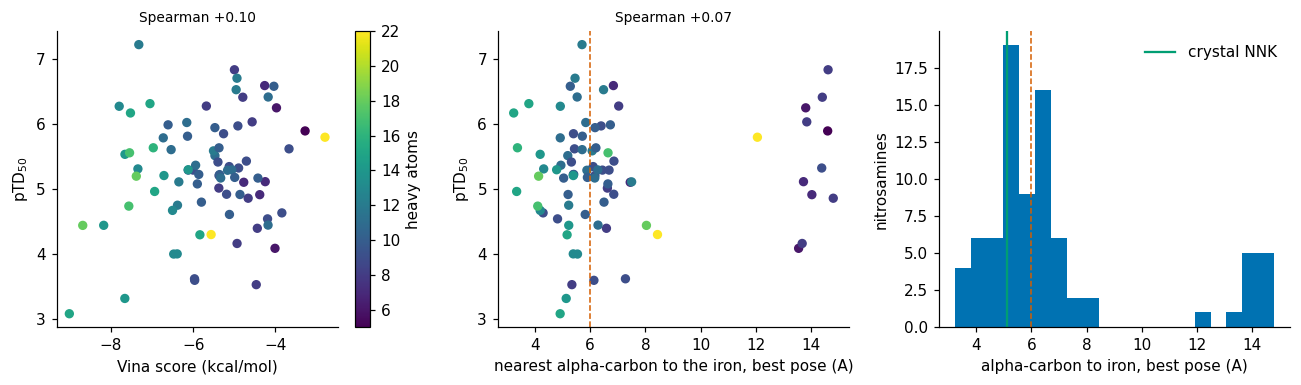

In [11]:
A = D[D.score.notna() & (D.group == "carcinogen")].copy(); print(f"{len(A)} carcinogens with a docking result")
rho_size = spearmanr(A.heavy, A.score)[0]; print(f"Spearman(heavy atoms, Vina score) = {rho_size:+.2f};  Spearman(heavy atoms, pTD50) = {spearmanr(A.heavy, A.ptd50)[0]:+.2f}")
B = A[A.d1.notna()]; tests = {}
tests["1. Vina score vs pTD50 [-]"] = spearman_test(A.score, A.ptd50); tests["2. Vina score vs pTD50, size removed [-]"] = partial_spearman_test(A.score, A.ptd50, A.heavy)
tests["3. alpha-C to Fe distance (best pose) vs pTD50 [-]"] = spearman_test(B.d1, B.ptd50); tests["4. fraction of reactive poses vs pTD50 [+]"] = spearman_test(B.frac_react, B.ptd50); tests["5. fraction of reactive poses vs pTD50, size removed [+]"] = partial_spearman_test(B.frac_react, B.ptd50, B.heavy)
TT = pd.DataFrame([dict(test=k, rho=v[0], p_perm=v[1], ci_low=v[2][0], ci_high=v[2][1]) for k, v in tests.items()]).set_index("test"); ALPHA = 0.05 / len(TT); TT["significant (Bonferroni)"] = TT.p_perm < ALPHA
print(TT.round(3).to_string()); print(f"\nthreshold after correction: p < {ALPHA:.3f}")
sub_rat = A[A.td50_src.isin(["cpdb", "lcdb"])]; print(f"\nrat-specific values only (n = {len(sub_rat)}):")
for nm_, f_ in {"Vina score vs pTD50": lambda d: spearman_test(d.score, d.ptd50, n_perm=5000, n_boot=500), "fraction of reactive poses vs pTD50": lambda d: spearman_test(d.frac_react, d.ptd50, n_perm=5000, n_boot=500), "fraction of reactive poses vs pTD50, size removed": lambda d: partial_spearman_test(d.frac_react, d.ptd50, d.heavy, n_perm=5000, n_boot=500)}.items(): r_ = f_(sub_rat[sub_rat.frac_react.notna()]); print(f"  {nm_}: rho {r_[0]:+.2f}, p {r_[1]:.3f}, 95% interval [{r_[2][0]:+.2f}, {r_[2][1]:+.2f}]")
for nm_ in ("NNK", "NNN", "DEN", "NDEA", "NDMA", "NMBA"):
    for _, r in A[A.name.str.contains(nm_, case=False, regex=False)].iterrows(): print(f"  {r['name'][:44]:44s} score {r.score:.2f}, alpha-C-Fe {r.d1:.1f} A, reactive poses {r.frac_react:.2f} | pTD50 {r.ptd50:.2f} (rank {int((A.ptd50 > r.ptd50).sum()) + 1} of {len(A)})")
if (D.group == "negative").any():
    N_ = D[(D.group == "negative") & D.frac_react.notna()]; u = mannwhitneyu(B.frac_react, N_.frac_react); print(f"\ncarcinogens vs negatives, fraction of reactive poses: medians {B.frac_react.median():.2f} vs {N_.frac_react.median():.2f}, Mann-Whitney p = {u.pvalue:.3f} (n = {len(B)} and {len(N_)})")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6)); sc = ax[0].scatter(A.score, A.ptd50, c=A.heavy, cmap="viridis", s=26); plt.colorbar(sc, ax=ax[0], label="heavy atoms"); ax[0].set_xlabel("Vina score (kcal/mol)"); ax[0].set_ylabel(r"pTD$_{50}$"); ax[0].set_title(f"Spearman {tests['1. Vina score vs pTD50 [-]'][0]:+.2f}", fontsize=9)
ax[1].scatter(B.d1, B.ptd50, c=B.heavy, cmap="viridis", s=26); ax[1].axvline(REACTIVE, color=COLORS["red"], ls="--", lw=1); ax[1].set_xlabel("nearest alpha-carbon to the iron, best pose (A)"); ax[1].set_ylabel(r"pTD$_{50}$"); ax[1].set_title(f"Spearman {tests['3. alpha-C to Fe distance (best pose) vs pTD50 [-]'][0]:+.2f}", fontsize=9)
ax[2].hist(B.d1, bins=20, color=COLORS["blue"]); ax[2].axvline(REACTIVE, color=COLORS["red"], ls="--", lw=1); ax[2].axvline(d_crystal, color=COLORS["green"], lw=1.5, label="crystal NNK"); ax[2].set_xlabel("alpha-carbon to iron, best pose (A)"); ax[2].set_ylabel("nitrosamines"); ax[2].legend(frameon=False); plt.tight_layout(); plt.show()

In [12]:
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
C_ = A[A.d1.notna() & A.frac_react.notna()].copy(); _gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024); FPB = np.array([_gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in C_.smiles], float)
def tanimoto_bits(X, Y): inter = X @ Y.T; return inter / np.maximum(X.sum(1)[:, None] + Y.sum(1)[None, :] - inter, 1e-9)
def leader_groups(sim, thr=0.5):
    g = -np.ones(len(sim), int); order = np.argsort(-(sim >= thr).sum(1)); k = 0
    for i in order:
        if g[i] >= 0: continue
        g[np.where((sim[i] >= thr) & (g < 0))[0]] = k; k += 1
    return g
S_ = tanimoto_bits(FPB, FPB); thr_ = 0.5; grp = leader_groups(S_, thr_)
while len(set(grp)) < 6 and thr_ > 0.2: thr_ -= 0.1; grp = leader_groups(S_, thr_)
folds = list(GroupKFold(5).split(FPB, C_.ptd50, grp)); y_ = C_.ptd50.values
def cv_rmse(X, y=y_):
    P = np.zeros(len(y))
    for tr, te in folds: P[te] = clone(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))).fit(X[tr], y[tr]).predict(X[te])
    return float(np.sqrt(np.mean((y - P) ** 2)))
mean_rmse = float(np.sqrt(np.mean(np.concatenate([(y_[te] - y_[tr].mean()) ** 2 for tr, te in folds]))))
base_cols = ["heavy", "logP", "tpsa", "rot"]; sets = {"size and polarity (heavy atoms, logP, TPSA, rotors)": base_cols, "Vina score only": ["score"], "geometry only (d1, frac_react)": ["d1", "frac_react"], "size and polarity + Vina score": base_cols + ["score"], "size and polarity + score + geometry": base_cols + ["score", "d1", "frac_react"]}
res_cv = {"mean prediction": mean_rmse, **{k: cv_rmse(C_[v].values) for k, v in sets.items()}}; print(f"{len(C_)} nitrosamines, {len(set(grp))} clusters (Tanimoto >= {thr_:.1f}); cross-validated RMSE of the pTD50:")
for k, v in res_cv.items(): print(f"  {k:55s} {v:.3f}")
gain = res_cv["size and polarity (heavy atoms, logP, TPSA, rotors)"] - res_cv["size and polarity + score + geometry"]; print(f"\nadding the score and the geometry to size and polarity changes the RMSE by {-gain:+.3f} (negative = better); noise between runs of such models is of the order of 0.03 to 0.05")
sig = TT["significant (Bonferroni)"]; useful = res_cv["size and polarity + score + geometry"] < 0.97 * mean_rmse and gain > 0.03
print("\nVERDICT: " + ("a correlation survives the correction for five tests (" + ", ".join(sig[sig].index) + "); check tests 2 and 5 for size" if sig.any() else "NO correlation of the docking score or of the activation geometry with the pTD50 survives the correction for five tests") + ("; the features do lower the cross-validated error below the mean prediction" if useful else "; the features do not improve the cross-validated prediction of the potency over the mean or over size and polarity descriptors"))

82 nitrosamines, 29 clusters (Tanimoto >= 0.5); cross-validated RMSE of the pTD50:
  mean prediction                                         0.850
  size and polarity (heavy atoms, logP, TPSA, rotors)     0.878
  Vina score only                                         0.881
  geometry only (d1, frac_react)                          0.861
  size and polarity + Vina score                          0.898
  size and polarity + score + geometry                    0.890

adding the score and the geometry to size and polarity changes the RMSE by +0.013 (negative = better); noise between runs of such models is of the order of 0.03 to 0.05

VERDICT: NO correlation of the docking score or of the activation geometry with the pTD50 survives the correction for five tests; the features do not improve the cross-validated prediction of the potency over the mean or over size and polarity descriptors


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8. Seeing the docked nitrosamines
Numbers hide the geometry, so this section draws the poses with **py3Dmol**. For any docked nitrosamine it shows:

* the **docked pose** (the best Vina pose; carbons in cyan), as sticks;
* **every residue with an atom within `cutoff` Å of the ligand** (5 Å by default; carbons in green), as sticks with labels, on a translucent cartoon of the nearby protein;
* the **crystal ligand** (NNK) as thin grey sticks, so that you can see whether the nitrosamine uses the same space;
* the **heme** (orange sticks, the iron as an orange sphere) and, as a dashed red line, the shortest distance from an **$\alpha$-carbon of the nitrosamine to the iron**, with its length in Å;
and a table of the residues that were found, with the shortest distance of each to the ligand. Choose the molecule in the dropdown, change the cutoff with the slider, and switch the crystal ligand on or off. The first time you choose a molecule whose pose has not been stored yet, the notebook **docks it again with the same settings** (about 20 seconds); the pose is then saved to `poses_cyp2a13.json`, together with its score, so the figure always shows the pose that the number belongs to. (Vina is seeded, but the 3D conformers that scrub makes may differ a little between runs, so this score can differ slightly from the one in the table of Section 6.)

How to read the picture, and what it cannot show: the pose is **one** Vina pose of a rigid-receptor calculation; the residues are those that *touch* the pose within the cutoff, not residues that make a favourable contact; water is absent; a hydrogen bond is not drawn, because Vina's polar hydrogens are not kept in the file. Draw conclusions about *which part of the molecule faces which residue*, not about energies.

An optional last cell docks **all** molecules that are missing from the store (20 to 30 minutes), counts how often each residue lies within the cutoff, and compares the 20 most potent with the 20 least potent nitrosamines. With 82 molecules and a docking score that is mostly size, treat any difference as a question to test, not as a finding.

**Stop and predict:** the most potent nitrosamines have small, simple substituents. Will they lie *deeper* in the pocket, touch *more* residues, or touch *fewer* residues than the large, weakly potent ones?

In [13]:
if importlib.util.find_spec("py3Dmol") is None: pip("py3Dmol")
import py3Dmol
from IPython.display import display, clear_output
import ipywidgets as widgets
from scipy.spatial.distance import cdist
CUT = 5.0; SHOW_CRYSTAL = True
SCORE_COL = "score"; POSE_FILE = "poses_cyp2a13.json"
POSE_STORE = json.load(open(POSE_FILE)) if os.path.isfile(POSE_FILE) else {}
def best_pose(smiles):
    """score and heavy-atom coordinates of the best pose; the molecule is docked again if its pose is not stored"""
    if smiles not in POSE_STORE:
        print("docking this molecule again to draw its pose ..."); pp = dock_poses(smiles); POSE_STORE[smiles] = [float(pp[0][0]), list(pp[0][1]), np.asarray(pp[0][2]).tolist()]; json.dump(POSE_STORE, open(POSE_FILE, "w"))
    s_, els_, xyz_ = POSE_STORE[smiles]; return s_, els_, np.asarray(xyz_, float)
REC_ATOMS = [a for a in parse_pdb("rec_in.pdb") if a["elem"] != "H"]; REC_XYZ = np.array([a["xyz"] for a in REC_ATOMS])
DISPLAY_ATOMS = [a for a in REC_ATOMS if np.linalg.norm(a["xyz"] - CENTER) <= 20.0]; DISPLAY_TEXT = "\n".join(a["line"] for a in DISPLAY_ATOMS) + "\nEND\n"      # the part of the receptor that is drawn (cartoon)
def pdb_line(serial, name, resn, chain, resi, xyz, elem):
    return f"HETATM{serial:5d} {name:<4} {resn:>3} {chain}{resi:4d}    {xyz[0]:8.3f}{xyz[1]:8.3f}{xyz[2]:8.3f}{1.0:6.2f}{0.0:6.2f}          {elem:>2}"
def pose_pdb_block(els, xyz, resn="LIG"):
    return "\n".join(pdb_line(k + 1, f"{el.upper()}{k + 1}"[:4], resn, "L", 1, p, el.upper() if len(el) == 1 else el) for k, (el, p) in enumerate(zip(els, xyz))) + "\nEND\n"
def residues_within(xyz, cutoff=CUT, atoms=None, rec_xyz=None):
    """residues of the receptor with at least one atom within `cutoff` A of any ligand atom: {(chain, resname, number): shortest distance}"""
    atoms = REC_ATOMS if atoms is None else atoms; R = REC_XYZ if rec_xyz is None else rec_xyz; dmin = cdist(R, np.asarray(xyz, float)).min(axis=1); out = {}
    for a, d in zip(atoms, dmin):
        if d <= cutoff: k = (a["chain"], a["resn"], a["resi"]); out[k] = min(float(d), out.get(k, 99.0))
    return out
def residue_centre(key):
    pts = [a["xyz"] for a in REC_ATOMS if (a["chain"], a["resn"], a["resi"]) == key and a["name"] not in ("N", "C", "O", "CA")] or [a["xyz"] for a in REC_ATOMS if (a["chain"], a["resn"], a["resi"]) == key]
    return np.mean(pts, axis=0)
def show_ligand(smiles, name="", cutoff=CUT, show_crystal=SHOW_CRYSTAL, width=760, height=560):
    score, els, xyz = best_pose(smiles); near = residues_within(xyz, cutoff); v = py3Dmol.view(width=width, height=height); m = 0
    v.addModel(DISPLAY_TEXT, "pdb"); v.setStyle({"model": m}, {"cartoon": {"color": "white", "opacity": 0.55}}); m += 1
    v.addModel("\n".join(a["line"] for a in heme_atoms) + "\nEND\n", "pdb"); v.setStyle({"model": m}, {"stick": {"radius": 0.15, "colorscheme": "orangeCarbon"}}); v.addStyle({"model": m, "elem": "Fe"}, {"sphere": {"radius": 0.7, "color": "orange"}}); m += 1
    if show_crystal: v.addModel("\n".join(a["line"] for a in lig_atoms) + "\nEND\n", "pdb"); v.setStyle({"model": m}, {"stick": {"radius": 0.07, "color": "gray"}}); m += 1
    v.addModel(pose_pdb_block(els, xyz), "pdb"); v.setStyle({"model": m}, {"stick": {"radius": 0.22, "colorscheme": "cyanCarbon"}}); m += 1
    for k in near:
        v.addStyle({"model": 0, "chain": k[0], "resi": k[2]}, {"stick": {"radius": 0.13, "colorscheme": "greenCarbon"}})
        c = residue_centre(k); v.addLabel(f"{k[1]}{k[2]}" + (f" ({k[0]})" if len({kk[0] for kk in near}) > 1 else ""), {"position": {"x": float(c[0]), "y": float(c[1]), "z": float(c[2])}, "fontSize": 11, "fontColor": "black", "backgroundColor": "white", "backgroundOpacity": 0.55, "borderThickness": 0, "inFront": True})
    ac = alpha_carbons_from_xyz(els, xyz); dfe = None
    if ac:
        P = np.asarray(xyz, float)[ac]; j = int(np.argmin(np.linalg.norm(P - FE, axis=1))); dfe = float(np.linalg.norm(P[j] - FE)); mid = (P[j] + FE) / 2
        v.addCylinder({"start": {"x": float(P[j][0]), "y": float(P[j][1]), "z": float(P[j][2])}, "end": {"x": float(FE[0]), "y": float(FE[1]), "z": float(FE[2])}, "radius": 0.06, "dashed": True, "color": "red", "fromCap": 1, "toCap": 1})
        v.addLabel(f"{dfe:.1f} A", {"position": {"x": float(mid[0]), "y": float(mid[1]), "z": float(mid[2])}, "fontSize": 12, "fontColor": "red", "backgroundColor": "white", "backgroundOpacity": 0.6, "inFront": True})
    v.zoomTo({"resn": "LIG"}); print(f"{name or smiles}: Vina score {score:.2f} kcal/mol; {len(near)} residues within {cutoff:.1f} A of the pose" + (f"; nearest alpha-carbon to the iron {dfe:.1f} A" if dfe is not None else "")); v.show()
    tab = pd.DataFrame([dict(residue=f"{k[1]}{k[2]}", chain=k[0], shortest_distance_A=round(d, 2)) for k, d in sorted(near.items(), key=lambda kv: kv[1])]); return tab
def label_for(r): return f"{str(r['name'])[:42]} | pTD50 {r['ptd50']:.2f} | score {r[SCORE_COL]:.2f}"
docked = D[D[SCORE_COL].notna() & (D.group == "carcinogen")].sort_values("ptd50", ascending=False); OPTIONS = [(label_for(r), r["smiles"]) for _, r in docked.iterrows()]
def gallery(patterns, **kw):
    """show several nitrosamines one after the other, chosen by a part of their names"""
    for p in patterns:
        hit = docked[docked["name"].str.contains(p, case=False, regex=False)]
        if len(hit): r = hit.iloc[0]; display(show_ligand(r["smiles"], r["name"], **kw))
        else: print("no docked nitrosamine has", p, "in its name")
# ---- interactive part
dd = widgets.Dropdown(options=OPTIONS, description="nitrosamine", layout=widgets.Layout(width="720px"), style={"description_width": "90px"})
sl = widgets.FloatSlider(value=CUT, min=3.0, max=8.0, step=0.5, description="cutoff (A)", style={"description_width": "90px"}); cb = widgets.Checkbox(value=SHOW_CRYSTAL, description="show the crystal ligand")
out = widgets.Output()
def refresh(*_):
    with out:
        clear_output(wait=True); name = next(l for l, s in OPTIONS if s == dd.value)
        try: display(show_ligand(dd.value, name, cutoff=sl.value, show_crystal=cb.value))
        except Exception as e_: print("could not draw this molecule:", type(e_).__name__, str(e_)[:200])
for w in (dd, sl, cb): w.observe(refresh, names="value")
display(widgets.VBox([dd, widgets.HBox([sl, cb]), out])); refresh()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

,residue,chain,shortest_distance_A
0,PHE107,E,3.51
1,PHE300,E,3.54
2,ASN297,E,3.54
3,ALA301,E,3.55
4,THR305,E,3.66
5,PHE111,E,3.74
6,PHE480,E,3.77
7,PHE118,E,3.89
8,LEU366,E,3.94
9,PHE209,E,3.94


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
RUN_ALL = False                 # True: dock every molecule that has no stored pose (20 to 30 minutes), then analyse the contacts
missing = [s for s in docked.smiles if s not in POSE_STORE]; print(f"{len(POSE_STORE)} poses stored, {len(missing)} missing")
if RUN_ALL:
    t0 = time.perf_counter()
    for k, s in enumerate(missing):
        try: best_pose(s)
        except Exception as e_: print("failed:", s, type(e_).__name__)
        if k % 10 == 9: print(f"  {k + 1}/{len(missing)} ({time.perf_counter() - t0:.0f} s)")
rows = []
for _, r in docked.iterrows():
    if r["smiles"] in POSE_STORE:
        _, els_, xyz_ = best_pose(r["smiles"])
        for k, d in residues_within(xyz_, CUT).items(): rows.append(dict(smiles=r["smiles"], ptd50=r["ptd50"], residue=f"{k[1]}{k[2]}", chain=k[0], d=d))
CT = pd.DataFrame(rows)
if CT.empty or CT.smiles.nunique() < 20: print("too few stored poses for a contact analysis: set RUN_ALL = True and run this cell again")
else:
    n_lig = CT.smiles.nunique(); freq = CT.groupby(["chain", "residue"]).smiles.nunique().sort_values(ascending=False) / n_lig; top = freq.head(15)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8)); ax[0].barh([f"{c}:{r}" for c, r in top.index][::-1], top.values[::-1], color=COLORS["green"]); ax[0].set_xlabel(f"fraction of the {n_lig} poses with an atom within {CUT} A"); ax[0].set_title("most frequent neighbours", fontsize=9)
    per = CT.groupby("smiles").size(); order = docked[docked.smiles.isin(per.index)].sort_values("ptd50", ascending=False); ax[1].scatter(order.ptd50, per.loc[order.smiles].values, s=24, color=COLORS["blue"]); ax[1].set_xlabel(r"pTD$_{50}$ (larger = more potent)"); ax[1].set_ylabel("residues within the cutoff"); ax[1].set_title("number of neighbours against potency", fontsize=9); plt.tight_layout(); plt.show()
    hi, lo = order.smiles.head(20), order.smiles.tail(20); f_hi = CT[CT.smiles.isin(hi)].groupby(["chain", "residue"]).smiles.nunique() / 20; f_lo = CT[CT.smiles.isin(lo)].groupby(["chain", "residue"]).smiles.nunique() / 20
    cmp_ = pd.concat([f_hi.rename("20 most potent"), f_lo.rename("20 least potent")], axis=1).fillna(0); cmp_["difference"] = cmp_["20 most potent"] - cmp_["20 least potent"]; print("residues whose contact frequency differs most between the two groups (not a statistical test):"); print(cmp_.reindex(cmp_.difference.abs().sort_values(ascending=False).index).head(8).round(2).to_string())
    print(f"Spearman(number of neighbours, pTD50) = {spearmanr(per.loc[order.smiles].values, order.ptd50)[0]:+.2f}; Spearman(number of neighbours, heavy atoms) = {spearmanr(per.loc[order.smiles].values, docked.set_index('smiles').loc[order.smiles, 'heavy'])[0]:+.2f}")

1 poses stored, 81 missing
too few stored poses for a contact analysis: set RUN_ALL = True and run this cell again


## 9. Your turn
**Exercise 1.** Sweep the reactive distance (`REACTIVE` = 5, 6, 7 Å) and re-run the analysis: is any conclusion sensitive to it? Choose the threshold *before* looking at the correlations, or report all three.

**Exercise 2.** Dock into CYP2A6 (PDB 4EJJ with nicotine; the active site is very similar) and into a structure of CYP2E1, the main activator of the small dialkylnitrosamines. Which enzyme gives the geometry that tracks the potency best? Remember to count how many hypotheses you have tested.

**Exercise 3.** Dock the 15 negatives (`DOCK_NEGATIVES = True`). Do they differ from the carcinogens in the geometry after the size correction?

**Exercise 4.** The crystal structure 4EJI has *two* NNK molecules, one in the active site and one in a distal site, and 4EJG has nicotine; use them as alternative receptor conformations (the helices move by about 2.5 Å). Does the ranking of the 82 nitrosamines depend on the receptor conformation (Spearman correlation between the two sets of scores)?

**Exercise 5.** Replace the geometry feature by a *reactivity-weighted* one: weigh each $\alpha$-carbon by the number of hydrogens it carries (from the SMILES; zero for an aryl or quaternary $\alpha$-carbon). Does a nitrosamine with no $\alpha$-hydrogens, which cannot be activated, now behave differently?

**Exercise 6.** Dock the same 82 molecules into a heme protein that does not metabolise nitrosamines (any other P450 pocket of similar size), and repeat the analysis. If its geometry features correlate with the pTD$_{50}$ as well as those of CYP2A13, the correlation belongs to the molecules, not to the enzyme.

## 10. Self-check

In [15]:
checks = []
def check(label, ok): checks.append((label, bool(ok))); print(("   ok   " if ok else "  FAIL  ") + label)
# --- pure-Python tools on synthetic data
ndma_el = ["N", "C", "C", "N", "O"]; ndma_xyz = np.array([[0, 0, 0], [1.46, 0, 0], [-0.7, 1.28, 0], [-0.6, -1.15, 0], [-0.2, -2.3, 0]], float)
check("alpha-carbons of N-nitrosodimethylamine are found from coordinates (indices 1 and 2)", alpha_carbons_from_xyz(ndma_el, ndma_xyz) == [1, 2])
check("a pyridine nitrogen or an amine without an N-nitroso group has no alpha-carbons", alpha_carbons_from_xyz(["N", "C", "C", "C"], np.array([[0, 0, 0], [1.4, 0, 0], [-0.7, 1.2, 0], [0, 0, 1.4]], float)) == [])
fe_t = np.array([5.0, 0.0, 0.0]); pm_t = pose_metrics([(-5.0, ndma_el, ndma_xyz), (-4.0, ndma_el, ndma_xyz + np.array([20, 0, 0]))], fe_t)
check("pose metrics: best score, distance of the nearest alpha-carbon to the iron, reactive fraction, score of the reactive poses", pm_t["score"] == -5.0 and abs(pm_t["d1"] - 3.54) < 0.05 and pm_t["frac_react"] == 0.5 and pm_t["score_react"] == -5.0)
hz = [dict(elem="Fe", name="FE", resn="HEM", chain="A", resi=500, xyz=np.array([1., 2., 3.])), dict(elem="C", name="C1A", resn="HEM", chain="A", resi=500, xyz=np.array([2., 2., 3.])), dict(elem="C", name="CMA", resn="HEM", chain="A", resi=500, xyz=np.array([3., 2., 3.])), dict(elem="N", name="NA", resn="HEM", chain="A", resi=500, xyz=np.array([1., 3., 3.])), dict(elem="O", name="O1A", resn="HEM", chain="A", resi=500, xyz=np.array([1., 2., 4.]))]
hl_t = heme_pdbqt(hz, 10); check("heme PDBQT: one line per atom, AutoDock types by element and name, coordinates and type in the right columns", [l[77:79].strip() for l in hl_t] == ["Fe", "A", "C", "N", "OA"] and abs(float(hl_t[0][30:38]) - 1.0) < 1e-6 and abs(float(hl_t[4][46:54]) - 4.0) < 1e-6)
pdb_txt = "\n".join(["ATOM      1  CA  PHE A 100      10.000  10.000  10.000  1.00  0.00           C", "HETATM    2  FE  HEM A 500       0.000   0.000   0.000  1.00  0.00          FE", "HETATM    3  C1  0QA A 600       5.000   0.000   0.000  1.00  0.00           C", "HETATM    4  N1  0QA A 600       6.000   0.000   0.000  1.00  0.00           N"])
at = parse_pdb(pdb_txt); check("PDB reader and ligand finder: iron read as Fe, a ligand found by composition", {a["elem"] for a in at} == {"C", "Fe", "N"} and list(find_ligands(at, {"C": 1, "N": 1})) == [("A", "0QA", 600)])
check("RMSD is zero for the same atoms in any order", heavy_rmsd(["C", "N"], np.array([[1., 0, 0], [2., 0, 0]]), ["N", "C"], np.array([[2., 0, 0], [1., 0, 0]])) < 1e-9)
pq = "MODEL 1\n" + pdbqt_line(1, "C1", "LIG", "A", 1, [1, 0, 0], 0.0, "A") + "\n" + pdbqt_line(2, "H1", "LIG", "A", 1, [2, 0, 0], 0.0, "HD") + "\nENDMDL\nMODEL 2\n" + pdbqt_line(1, "C1", "LIG", "A", 1, [9, 9, 9], 0.0, "A") + "\nENDMDL"
e_, x_ = read_pdbqt_pose(pq, 2); check("PDBQT reader: the second model, hydrogens dropped", e_ == ["C"] and np.allclose(x_, [[9, 9, 9]]))
cl_ = [pdbqt_line(1, "SG", "CYS", "A", 7, [0, 0, 2.3], 0.0, "SA"), pdbqt_line(2, "HG", "CYS", "A", 7, [0, 0, 3.4], 0.0, "HD"), pdbqt_line(3, "SG", "CYS", "A", 9, [20, 0, 0], 0.0, "SA"), pdbqt_line(4, "HG", "CYS", "A", 9, [20, 0, 1.3], 0.0, "HD")]; kept_ = strip_cys_hg(cl_, np.array([0., 0., 0.]))
check("the hydrogen of the iron-binding cysteine is removed and that of another cysteine is kept", len(kept_) == 3 and not any(l[12:16].strip() == "HG" and l[22:26].strip() == "7" for l in kept_))
rg_ = np.random.default_rng(1); zz = rg_.normal(size=200); xx = zz + 0.3 * rg_.normal(size=200); yy = zz + 0.3 * rg_.normal(size=200); r1 = spearman_test(xx, yy, n_perm=500, n_boot=200); r2 = partial_spearman_test(xx, yy, zz, n_perm=500, n_boot=200)
check("statistics: a strong common-cause correlation is found, and mostly disappears when the cause is removed", r1[0] > 0.7 and r1[1] < 0.01 and abs(r2[0]) < 0.3 and abs(r2[0]) < 0.4 * r1[0])
rs_ = [dict(chain="A", resn="TRP", resi=1, xyz=np.array([0., 0, 3.0]), elem="C"), dict(chain="A", resn="GLY", resi=2, xyz=np.array([0., 0, 7.0]), elem="C"), dict(chain="B", resn="TYR", resi=3, xyz=np.array([4.9, 0, 0]), elem="C")]
near_ = residues_within(np.array([[0., 0, 0]]), 5.0, atoms=rs_, rec_xyz=np.array([a["xyz"] for a in rs_]))
check("residues within the cutoff: the two residues closer than 5 A are found, the one at 7 A is not", set(near_) == {("A", "TRP", 1), ("B", "TYR", 3)} and abs(near_[("A", "TRP", 1)] - 3.0) < 1e-6)
pb_ = parse_pdb(pose_pdb_block(["C", "N", "Cl"], np.array([[1., 2, 3], [4, 5, 6], [7, 8, 9]]))); check("the pose block is valid PDB: elements and coordinates survive a round trip", [a["elem"] for a in pb_] == ["C", "N", "Cl"] and np.allclose(pb_[2]["xyz"], [7, 8, 9]))
# --- the real run
check("82 carcinogens and 15 negatives in the embedded tables", len(POS) == 82 and len(NEG) == 15)
check("the structure has a heme with an iron in the chain of the active-site NNK", CHAIN in fe_by_chain and any(a["elem"] == "Fe" for a in heme_atoms))
check("the active-site NNK is within 7 A of the iron and has two alpha-carbons in the crystal", d_fe_lig < 7.0 and len(ac_idx) == 2 and d_crystal < 8.0)
check("the active site has at least 3 phenylalanines near the ligand", n_phe >= 3)
check("the receptor file contains the heme (iron included, or removed on purpose with a message)", any(l[77:79].strip() == "Fe" for l in open("receptor.pdbqt")) or os.path.isfile("receptor_noFe.pdbqt"))
check("redocked NNK is within 3 A of the crystal position", centroid_shift < 3.0)
check("scores are finite and negative for at least 90% of the ligands", (D.score.notna() & (D.score < 0)).mean() >= 0.9)
check("an alpha-carbon was identified in the poses of at least 90% of the docked ligands", D.d1.notna().sum() >= 0.9 * D.score.notna().sum())
check("the figure code finds at least 8 residues within 5 A of the crystal ligand", len(residues_within(LIG_XYZ)) >= 8)
print(f"\ninformation: redocking RMSD {rmsd_nnk:.2f} A, crystal alpha-C to iron {d_crystal:.2f} A; Spearman(score, pTD50) {tests['1. Vina score vs pTD50 [-]'][0]:+.2f}, (reactive fraction, pTD50) {tests['4. fraction of reactive poses vs pTD50 [+]'][0]:+.2f}")
assert all(ok_ for _, ok_ in checks); print("All checks passed.")

   ok   alpha-carbons of N-nitrosodimethylamine are found from coordinates (indices 1 and 2)
   ok   a pyridine nitrogen or an amine without an N-nitroso group has no alpha-carbons
   ok   pose metrics: best score, distance of the nearest alpha-carbon to the iron, reactive fraction, score of the reactive poses
   ok   heme PDBQT: one line per atom, AutoDock types by element and name, coordinates and type in the right columns
   ok   PDB reader and ligand finder: iron read as Fe, a ligand found by composition
   ok   RMSD is zero for the same atoms in any order
   ok   PDBQT reader: the second model, hydrogens dropped
   ok   the hydrogen of the iron-binding cysteine is removed and that of another cysteine is kept
   ok   statistics: a strong common-cause correlation is found, and mostly disappears when the cause is removed
   ok   residues within the cutoff: the two residues closer than 5 A are found, the one at 7 A is not
   ok   the pose block is valid PDB: elements and coordinates s

### What to look for
* **The redocking first.** If NNK does not return to its crystal pose, and above all if the redocked $\alpha$-carbon to iron distance is far from the crystal value, the geometry features are not trustworthy. A centroid within 2 Å but an RMSD above 2 Å usually means that the pocket is found but the orientation is not, which is exactly what the geometry depends on.
* **The distribution of the distance.** The histogram shows how many of the 82 molecules can place an $\alpha$-carbon near the iron at all. If almost every molecule does, in a small pocket, the feature has little room to discriminate.
* **Size.** The Vina score depends strongly on the number of heavy atoms; the geometry features may too (a bigger molecule has more $\alpha$-carbons and more orientations in a small pocket). Tests 2 and 5 exist for that reason.
* **Multiple testing.** Five tests are reported; a $p$-value of 0.03 is not a finding. Choose the thresholds and the enzyme before looking, and count every variant you try.
* **What a positive result would still not show.** That CYP2A13 activates the compound, at what rate, or that the rate sets the potency; CYP2A13 is mostly a respiratory enzyme, and the rat TD$_{50}$ values come mostly from other tissues and other enzymes. A reasonable follow-up is CYP2E1 and CYP2B (Exercise 2) and the negative-control protein of Exercise 6.
* **What a null result shows.** That in this pocket, with this scoring, neither the binding estimate nor the activation geometry carries a potency signal beyond size: consistent with the finding of B7n and B7o that structure alone does not predict the potency of these compounds, and with the view that the potency depends on much more than the first encounter of substrate and enzyme.
* **Limits of the method.** One rigid enzyme conformation of eight in the crystal; no induced fit, no water, no electronics of the heme or of the C–H bond; Vina without a metal term; a human enzyme for rat data; 82 data points.
* **Citations to check.** Smith *et al.*, *J. Biol. Chem.* 2007 (structure of CYP2A13); DeVore and Scott, *J. Biol. Chem.* 2012;287:26576 (nicotine and NNK complexes; PDB 4EJG, 4EJH, 4EJI, 4EJJ); Eberhardt *et al.*, *J. Chem. Inf. Model.* 2021 (AutoDock Vina 1.2); the Meeko software of the Forli laboratory.